In [ ]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test
from scipy.stats import linregress

# ========= 输出路径 =========
OUT_DIR = r"C:\greenland\1995bu\fig4"
os.makedirs(OUT_DIR, exist_ok=True)

# ========= 文件路径 =========
files = {
    "t2m":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc",
    "strd": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc",
    "ssrd": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland202209.nc",
    "rf":   r"C:\greenland\sf_tp_rf.nc",
    "tcc":  r"C:\Users\greenlandProject\ERA5LAND\greenland_tcc_full.nc",
}

# ========= 函数 =========
def calc_summer_mean(ds, varname):
    """提取夏季 (JJA) 年度均值"""
    time_name = "valid_time" if "valid_time" in ds.coords else "time"
    da = ds[varname]
    da = da.assign_coords(time=ds[time_name])
    da = da.swap_dims({time_name: "time"})
    da["month"] = da["time"].dt.month
    da["year"] = da["time"].dt.year
    da_summer = da.where(da["month"].isin([6,7,8]), drop=True)
    summer_mean = da_summer.groupby("year").mean(dim="time", skipna=True)
    return summer_mean

def mk_trend_per_decade(y):
    y = np.array(y)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_grid_mean_trend(da):
    """计算每格点均值 + MK趋势"""
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    lats = da[lat_name].values
    lons = da[lon_name].values
    
    mean_map = da.mean(dim="year", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["year"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )
    
    LAT, LON = np.meshgrid(lats, lons, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

def compute_sliding_trend(years, series):
    n = len(years)
    trend_matrix = np.full((n, n), np.nan)
    for i in range(n - 1):
        for j in range(i + 1, n):
            y = series[i:j+1]
            if np.isnan(y).sum() < len(y) - 2:
                slope, _, _, _, _ = linregress(np.arange(len(y)), y)
                trend_matrix[i, j] = slope
    df = pd.DataFrame(trend_matrix, index=years, columns=years)
    return df

# ========= 主循环 =========
for var, path in files.items():
    print(f"\n===== Processing {var} =====")
    
    # ✅ 检查CSV是否已存在（只检查一个，因为两个总是同时生成）
    out_meantrend = os.path.join(OUT_DIR, f"Greenland_{var}_MeanTrend.csv")
    out_slide = os.path.join(OUT_DIR, f"Greenland_{var}_SlidingTrend.csv")
    
    if os.path.exists(out_meantrend):
        print(f"⏭️  {var} 的CSV已存在，跳过")
        continue
    
    # 打开数据集
    ds = xr.open_dataset(path)
    if var not in ds.data_vars:
        print(f"⚠️  Variable {var} not found in {path}")
        ds.close()
        continue
    
    da = calc_summer_mean(ds, var)
    ds.close()
    print(f"✅ Summer mean shape: {da.shape}")
    
    # ---- 均值 + MK 趋势 ----
    print("⏳ Calculating MK trend per grid...")
    df_mt = compute_grid_mean_trend(da)
    df_mt.to_csv(out_meantrend, index=False)
    print(f"💾 Saved: {out_meantrend}")
    
    # ---- 滑动趋势 ----
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    area_mean = da.mean(dim=[lat_name, lon_name], skipna=True).values
    years = da.year.values
    
    print("⏳ Calculating sliding trends...")
    df_slide = compute_sliding_trend(years, area_mean)
    df_slide.to_csv(out_slide, index=True)
    print(f"💾 Saved: {out_slide}")

print("\n✅ 全部5个变量（t2m, strd, ssrd, rf, tcc）处理完成！结果保存在 C:\\greenland\\1995bu\\fig4")


===== Processing t2m =====
⏭️  t2m 的CSV已存在，跳过

===== Processing strd =====
⏭️  strd 的CSV已存在，跳过

===== Processing ssrd =====
⏭️  ssrd 的CSV已存在，跳过

===== Processing rf =====
⏭️  rf 的CSV已存在，跳过

===== Processing tcc =====
⏭️  tcc 的CSV已存在，跳过

✅ 全部5个变量（t2m, strd, ssrd, rf, tcc）处理完成！结果保存在 C:\greenland\1995bu\fig4


In [ ]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test
from scipy.stats import linregress

# ========= 输出路径 =========
OUT_DIR = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile"
os.makedirs(OUT_DIR, exist_ok=True)

# ========= 文件路径 =========
files = {
    "sf":   r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\sf_tp_rf.nc",
    "tp":   r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\sf_tp_rf.nc",
    "hcc":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc",
    "lcc":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc",
    "vimdf": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc",
}

# ========= 函数 =========
def calc_summer_mean(ds, varname):
    """提取每年夏季(JJA)均值"""
    time_name = "valid_time" if "valid_time" in ds.coords else "time"
    da = ds[varname]
    da = da.assign_coords(time=ds[time_name])
    da = da.swap_dims({time_name: "time"})
    da["month"] = da["time"].dt.month
    da["year"] = da["time"].dt.year
    da_summer = da.where(da["month"].isin([6,7,8]), drop=True)
    da_summer_mean = da_summer.groupby("year").mean(dim="time", skipna=True)
    return da_summer_mean

def mk_trend_per_decade(y):
    """对单点时间序列做MK趋势检验"""
    y = np.array(y)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_grid_mean_trend(da):
    """计算每格点多年均值 + MK趋势"""
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    lats = da[lat_name].values
    lons = da[lon_name].values
    
    mean_map = da.mean(dim="year", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["year"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )
    
    LAT, LON = np.meshgrid(lats, lons, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

def compute_sliding_trend(years, series):
    """计算滑动趋势矩阵"""
    n = len(years)
    trend_matrix = np.full((n, n), np.nan)
    for i in range(n - 1):
        for j in range(i + 1, n):
            y = series[i:j+1]
            if np.isnan(y).sum() < len(y) - 2:
                slope, _, _, _, _ = linregress(np.arange(len(y)), y)
                trend_matrix[i, j] = slope
    df = pd.DataFrame(trend_matrix, index=years, columns=years)
    return df

# ========= 主循环 =========
for var, path in files.items():
    print(f"\n===== Processing {var} =====")
    
    out_meantrend = os.path.join(OUT_DIR, f"Greenland_{var}_MeanTrend.csv")
    out_slide = os.path.join(OUT_DIR, f"Greenland_{var}_SlidingTrend.csv")
    
    if os.path.exists(out_meantrend):
        print(f"⏭️  {var} 的CSV已存在，跳过")
        continue

    # 打开文件
    ds = xr.open_dataset(path)
    if var not in ds.data_vars:
        print(f"⚠️  Variable {var} not found in {path}")
        ds.close()
        continue

    da = calc_summer_mean(ds, var)
    ds.close()
    print(f"✅ Summer mean shape: {da.shape}")

    # ---- 均值 + MK趋势 ----
    print("⏳ Calculating MK trend per grid...")
    df_mt = compute_grid_mean_trend(da)
    df_mt.to_csv(out_meantrend, index=False)
    print(f"💾 Saved: {out_meantrend}")

    # ---- 滑动趋势 ----
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    area_mean = da.mean(dim=[lat_name, lon_name], skipna=True).values
    years = da.year.values

    print("⏳ Calculating sliding trends...")
    df_slide = compute_sliding_trend(years, area_mean)
    df_slide.to_csv(out_slide, index=True)
    print(f"💾 Saved: {out_slide}")

print("\n✅ 新的5个变量（sf, tp, hcc, lcc, vimdf）处理完成！结果保存在 C:\\Users\\greenlandProject\\ERA5LAND\\ProcessFile")



===== Processing sf =====


In [ ]:
import numpy as np
import pandas as pd
import xarray as xr
from sklearn.linear_model import LinearRegression

# ===== 路径 (Path - 请根据你的实际路径修改) =====
nc_path = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
output_path = r"C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.csv"

# ===== 1. 读取并计算格陵兰平均 Albedo =====
try:
    ds = xr.open_dataset(nc_path)
except FileNotFoundError:
    print(f"ERROR: File not found at {nc_path}. Please check the path.")
    exit()

# 自动识别包含"albedo"的变量名
varname = [v for v in ds.data_vars if "albedo" in v.lower()][0]
da = ds[varname]
albedo_mean = da.mean(dim=("lat", "lon"), skipna=True)

# ===== 2. 识别时间维度 =====
time_values = albedo_mean["time"].values
if np.issubdtype(time_values.dtype, np.number):
    years = np.array(time_values).astype(int)
else:
    # 提取年份
    years = pd.to_datetime(time_values).year
vals = albedo_mean.values
print(f"✅ Data range: {years.min()}–{years.max()} ({len(years)} years)")

# ===== 3. 计算滑动趋势矩阵（右上角结构） =====
n = len(years)
# 初始化一个全为 NaN 的矩阵
trend_matrix = np.full((n, n), np.nan) 

# 外层循环: Start Year index (对应矩阵的行 i)
for i in range(n): 
    # 内层循环: End Year index (对应矩阵的列 j)
    # 确保时段长度至少为 3 年 (j - i + 1 >= 3)，所以 j >= i + 2
    for j in range(i + 2, n): 
        
        # 截取从 i 到 j (包含 j) 的年份和数据
        x = np.array(years[i:j+1]).reshape(-1, 1) # 时间变量 (自变量)
        y = vals[i:j+1]                           # Albedo 值 (因变量)
        
        # 确保有足够多的有限值来进行线性回归 (至少2个点，但我们要求至少3年)
        if np.isfinite(y).sum() >= 2: 
            model = LinearRegression().fit(x, y)
            # 将趋势值存入矩阵的 [Start Year Index, End Year Index]，即右上角
            trend_matrix[i, j] = model.coef_[0] 
        else:
            # 如果数据点不足，保持为 NaN
            trend_matrix[i, j] = np.nan

# ===== 4. 创建 DataFrame 并保存为 CSV =====
# 创建 DataFrame，行索引和列索引都是年份
df = pd.DataFrame(trend_matrix, index=years, columns=years)

# 保存为 CSV 文件
df.to_csv(output_path, index=True, na_rep='')
print(f"✅ CSV file saved to: {output_path}")

# 显示前几行预览
print("\n前5行5列预览:")
print(df.iloc[:5, :5])

ds.close() # 关闭 xarray 数据集


✅ Data range: 1950–2024 (75 years)
✅ CSV file saved to: C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.csv

前5行5列预览:
      1950  1951      1952      1953      1954
1950   NaN   NaN  0.004835  0.002649  0.002529
1951   NaN   NaN       NaN -0.001646  0.000322
1952   NaN   NaN       NaN       NaN  0.002311
1953   NaN   NaN       NaN       NaN       NaN
1954   NaN   NaN       NaN       NaN       NaN


In [ ]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test

# ========= 文件路径与输出路径 =========
NC_PATH  = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_PATH = r"C:\greenland\1995bu\fig4\Greenland_alb_MeanTrend.csv"

# ========= 函数定义 =========
def mk_trend_per_decade(y):
    """对每个像元时间序列做 Mann-Kendall 趋势检验，返回每十年变化率"""
    y = np.array(y, dtype=float)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_mean_trend(da):
    """计算均值和MK趋势"""
    lat = da["lat"].values
    lon = da["lon"].values

    mean_map = da.mean(dim="time", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["time"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )

    LAT, LON = np.meshgrid(lat, lon, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

# ========= 主程序 =========
print("===== Processing Greenland albedo =====")

ds = xr.open_dataset(NC_PATH)
da = ds["albedo"]

print(f"✅ 数据读取完成: {da.shape}, dims={list(da.dims)}")

df = compute_mean_trend(da)

# ========= 输出 =========
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
df.to_csv(OUT_PATH, index=False)
print(f"💾 已保存: {OUT_PATH}")
print("\n✅ 完成！文件内容包含 lat, lon, mean, trend_per_decade 四列。")



────────────────────────────────────────────────────────────────────────────────
【文件路径】
────────────────────────────────────────────────────────────────────────────────
C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc

────────────────────────────────────────────────────────────────────────────────
【基本打开（decode_cf=False / True）】
────────────────────────────────────────────────────────────────────────────────

────────────────────────────────────────────────────────────────────────────────
【数据集基本信息（decode_cf=False）】
────────────────────────────────────────────────────────────────────────────────
  data_vars: ['albedo']
  coords:    ['lat', 'lon', 'time']
  dims:      {'lat': 237, 'lon': 612, 'time': 75}
  dataset attrs (0):
    (no attrs)

────────────────────────────────────────────────────────────────────────────────
【数据集基本信息（decode_cf=True）】
────────────────────────────────────────────────────────────────────────────────
  data_vars: ['albedo']
  coords:    ['lat', 'lon', 'tim

C:\Users\11823\AppData\Local\Temp\ipykernel_63824\2128983320.py:148: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"  dims:      {dict(ds_raw.dims)}")
C:\Users\11823\AppData\Local\Temp\ipykernel_63824\2128983320.py:155: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"  dims:      {dict(ds_cf.dims)}")


In [20]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test

# ========= 输出路径 =========
OUT_DIR = r"C:\greenland\1995bu\fig4"
os.makedirs(OUT_DIR, exist_ok=True)

# ========= Albedo数据路径 =========
ALBEDO_PATH = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"

def mk_trend_with_sig_1d(y):
    """对一条时间序列做 MK，返回(每十年趋势, 是否显著95%)"""
    y = np.asarray(y, dtype=float)
    valid = np.isfinite(y)
    if valid.sum() < 8:
        return np.nan, np.nan
    try:
        res = original_test(y[valid])
        trend_per_decade = res.slope * 10.0
        sig95 = 1.0 if res.p < 0.05 else 0.0
        return trend_per_decade, sig95
    except Exception:
        return np.nan, np.nan

def prepare_year_da(ds, varname="albedo"):
    """
    你的文件 time=75 且没CF时间属性 => time 很可能就是年份轴(1950..2024)或可直接当年份用。
    这里把 time -> year，得到维度 (year, lat, lon) 或 (year, latitude, longitude)。
    """
    if varname not in ds.data_vars:
        raise KeyError(f"找不到变量 {varname}，当前 data_vars={list(ds.data_vars)}")

    da = ds[varname]

    # 统一坐标名
    if "lat" in da.coords and "latitude" not in da.coords:
        da = da.rename({"lat": "latitude"})
    if "lon" in da.coords and "longitude" not in da.coords:
        da = da.rename({"lon": "longitude"})

    # time -> year
    if "time" not in da.dims:
        raise KeyError(f"{varname} 没有 time 维度，当前 dims={da.dims}")

    t = da["time"].values

    # 情况A：time 已经是 datetime64
    if np.issubdtype(da["time"].dtype, np.datetime64):
        year = xr.DataArray(da["time"].dt.year.values, dims=("time",), name="year")
    else:
        # 情况B：time 不是 datetime：大概率就是年份索引（75个）
        # 尝试直接转 int（比如 [1950,1951,...]）
        try:
            year_vals = t.astype(int)
        except Exception:
            # 万一是 float 或字符串
            year_vals = pd.to_numeric(t).astype(int)

        # 基本 sanity check：像不像年份
        if year_vals.min() < 1800 or year_vals.max() > 2200:
            raise TypeError(
                f"time 不是 datetime，且转成 int 后不像年份：min={year_vals.min()}, max={year_vals.max()}。\n"
                "你这个文件缺少 CF 时间单位（units/calendar）。需要你提供 time 的原始取值（print(ds.time.values[:10])）。"
            )
        year = xr.DataArray(year_vals, dims=("time",), name="year")

    da = da.assign_coords(year=year).swap_dims({"time": "year"}).drop_vars("time")
    return da

def main():
    print("===== 处理2001-2024年Albedo（夏季）均值+MK趋势+sig95 =====")

    out_file = os.path.join(OUT_DIR, "Greenland_2001_2024_albedo_MeanTrend_sig95.csv")
    if os.path.exists(out_file):
        print(f"⏭️ 文件已存在: {out_file}")
        print("如需重新计算，请先删除该文件")
        return

    if not os.path.exists(ALBEDO_PATH):
        print(f"❌ 找不到文件: {ALBEDO_PATH}")
        return

    ds = xr.open_dataset(ALBEDO_PATH)

    # 你的文件 data_vars 就是 ['albedo']，这里直接用
    varname = "albedo" if "albedo" in ds.data_vars else list(ds.data_vars)[0]
    print(f"✅ 使用变量: {varname}")

    da_year = prepare_year_da(ds, varname=varname)
    ds.close()

    # 子集：2001-2024
    da_sub = da_year.sel(year=slice(2001, 2024))

    print(f"✅ year范围: {int(da_sub.year.min())} - {int(da_sub.year.max())}")
    print(f"✅ 形状(year,lat,lon): {da_sub.shape}")

    # 多年平均（2001-2024）
    print("⏳ 计算均值...")
    mean_map = da_sub.mean(dim="year", skipna=True)

    # MK 趋势 & 显著性（向量化到每个格点）
    print("⏳ 计算MK趋势和显著性（vectorized）...")
    trend_map, sig_map = xr.apply_ufunc(
        mk_trend_with_sig_1d,
        da_sub,
        input_core_dims=[["year"]],
        output_core_dims=[[], []],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[np.float32, np.float32],
    )

    # 展平输出
    lats = mean_map["latitude"].values
    lons = mean_map["longitude"].values
    LAT, LON = np.meshgrid(lats, lons, indexing="ij")

    df = pd.DataFrame({
        "lat": LAT.ravel(),
        "lon": LON.ravel(),
        "mean": mean_map.values.ravel(),
        "trend_per_decade": trend_map.values.ravel(),
        "trend_sig95": sig_map.values.ravel(),
    })

    # 去掉全空行
    df = df.dropna(subset=["mean", "trend_per_decade", "trend_sig95"], how="all")

    print(f"💾 保存到: {out_file}")
    df.to_csv(out_file, index=False, float_format="%.6f")

    print("\n📊 统计信息:")
    print(f"总格点数: {len(df)}")
    if len(df):
        print(f"均值范围: [{df['mean'].min():.3f}, {df['mean'].max():.3f}]")
        print(f"趋势范围: [{df['trend_per_decade'].min():.4f}, {df['trend_per_decade'].max():.4f}] 每十年")
        sig_count = float(np.nansum(df["trend_sig95"].values))
        print(f"显著趋势格点数: {sig_count:.0f} ({sig_count/len(df)*100:.1f}%)")

    print("\n✅ 完成")

if __name__ == "__main__":
    main()


===== 处理2001-2024年Albedo（夏季）均值+MK趋势+sig95 =====
✅ 使用变量: albedo
✅ year范围: 2001 - 2024
✅ 形状(year,lat,lon): (24, 237, 612)
⏳ 计算均值...
⏳ 计算MK趋势和显著性（vectorized）...
💾 保存到: C:\greenland\1995bu\fig4\Greenland_2001_2024_albedo_MeanTrend_sig95.csv

📊 统计信息:
总格点数: 65472
均值范围: [0.178, 0.863]
趋势范围: [-0.0959, 0.0510] 每十年
显著趋势格点数: 22675 (34.6%)

✅ 完成


✅ Shapefiles loaded: 9 basins | 4 contours


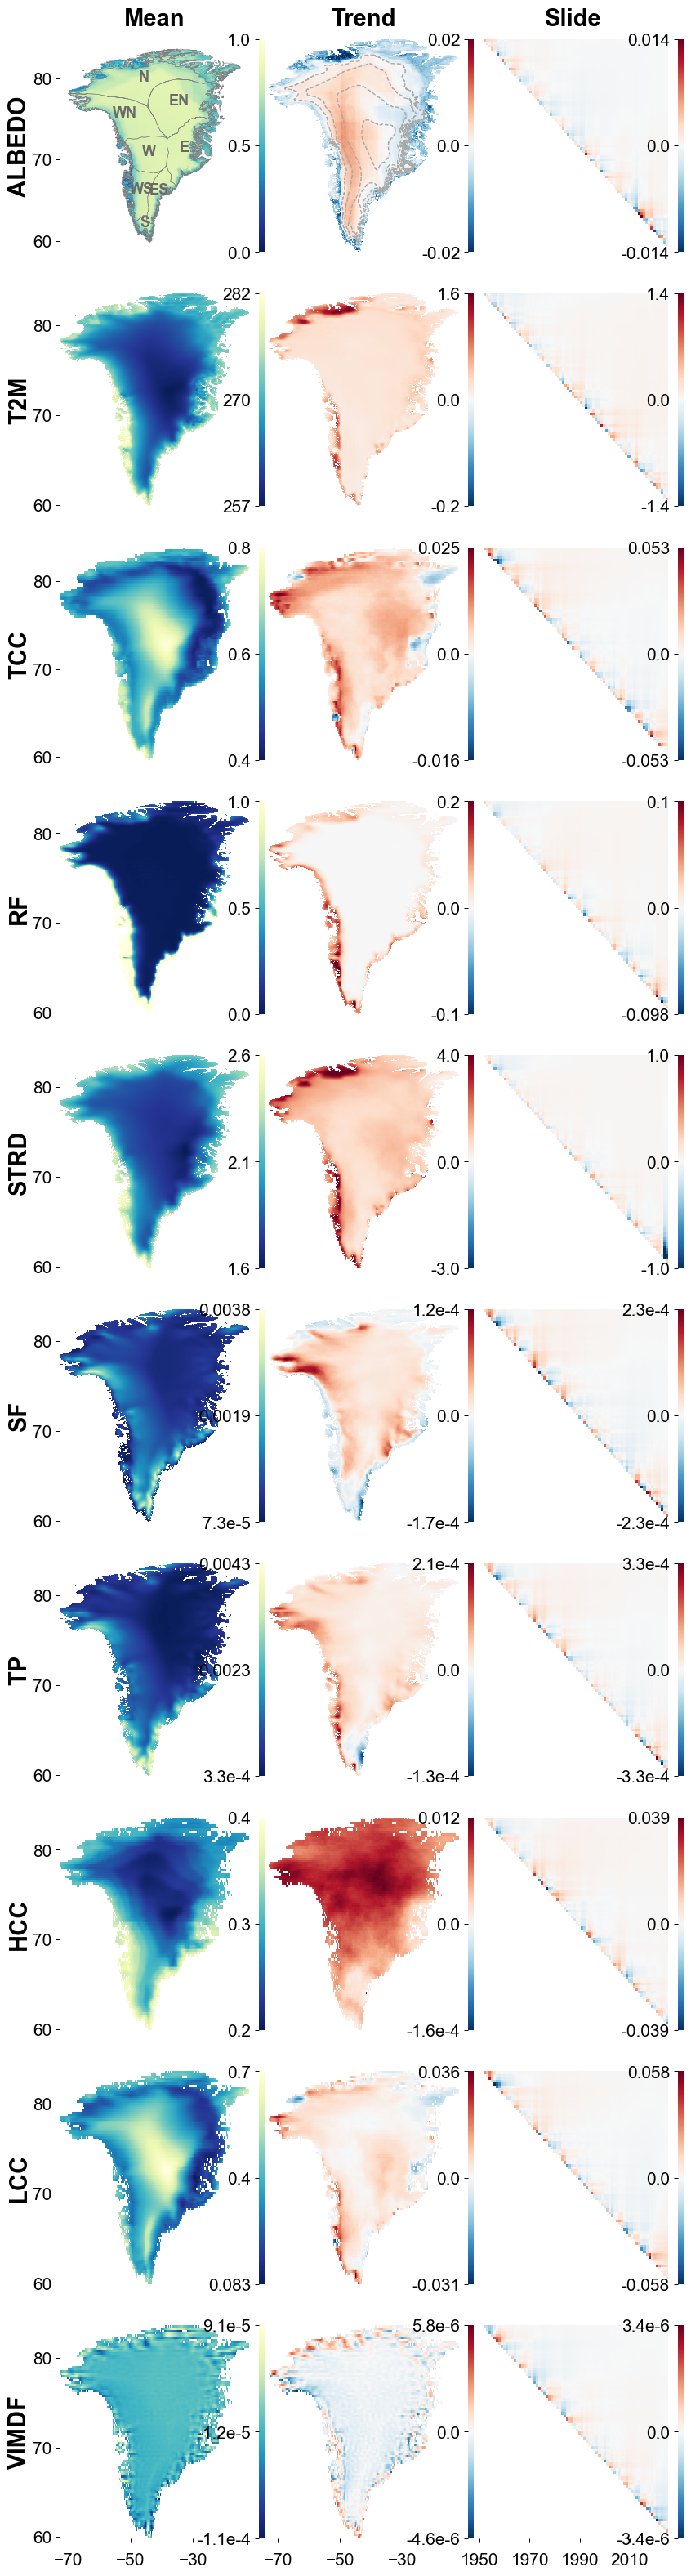

In [ ]:
# -*- coding: utf-8 -*-
"""
Final 5×3 Greenland Climate Panel
(ALB fixed aspect ratio, no deformation, thicker contours)

【修改版 v7.3：统一 "Mean" 列配色为 'YlGnBu_r' (亮色代表高值)】
"""

import os
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mcolors
from shapely.geometry import LineString, MultiLineString

# ===== 参数区 =====
FONT_SIZE = 19
TICK_FONT_SIZE = FONT_SIZE - 4 # 15
TITLE_SIZE = FONT_SIZE + 2
HSPACE = 0.015
WSPACE = 0.03
TOP_ALIGN = 0.96
DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = os.path.join(DATA_DIR, "Fig4_10x3panel_final_v7_ticks_refined.png") # (路径保持v7)

# shapefile路径
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7
})

# ========== 加载 shapefile ==========
abbr_map = {
    "WestSouth": "WS", "WestNorth": "WN", "West": "W",
    "Melt": "M", "EastSouth": "ES", "EastNorth": "EN",
    "East": "E", "North": "N", "South": "S"
}

basins_list = []
for fname in os.listdir(BASIN_DIR):
    if fname.lower().endswith(".shp"):
        gdf = gpd.read_file(os.path.join(BASIN_DIR, fname))
        if gdf.crs and gdf.crs.to_string() != "EPSG:4326":
            gdf = gdf.to_crs("EPSG:4326")
        gdf["abbr"] = abbr_map.get(os.path.splitext(fname)[0], fname)
        basins_list.append(gdf)
basins_all = pd.concat(basins_list, ignore_index=True)

contour_gdf = gpd.read_file(CONTOUR_PATH)
if contour_gdf.crs and contour_gdf.crs.to_string() != "EPSG:4326":
    contour_gdf = contour_gdf.to_crs("EPSG:4326")

print(f"✅ Shapefiles loaded: {len(basins_all)} basins | {len(contour_gdf)} contours")

# ========== 图框布局 ==========
fig = plt.figure(figsize=(8.1, 33.6))

VARS = ["albedo", "t2m", "tcc", "rf", "strd",
        "sf", "tp", "hcc", "lcc", "vimdf"]
COL_NAMES = ["Mean", "Trend", "Slide"]

n_rows, n_cols = len(VARS), len(COL_NAMES)
left_margin, right_margin, bottom_margin = 0.05, 0.97, 0.05
total_width = right_margin - left_margin
available_width = total_width - (n_cols - 1) * WSPACE
w = available_width / n_cols
h = (TOP_ALIGN - bottom_margin - (n_rows - 1) * HSPACE) / n_rows
axes = []

PAD_TITLE = 12
PAD_XAXIS = 9

# ========== 绘图循环 ==========
for i, var in enumerate(VARS):
    for j, col in enumerate(COL_NAMES):
        left = left_margin + j * (w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        ax = fig.add_axes([left, bottom, w, h])
        axes.append(ax)
        
        for spine in ax.spines.values():
            spine.set_visible(False)
        
        CBAR_WIDTH, CBAR_PAD = "3%", 0.08 

        meantrend_csv = os.path.join(DATA_DIR, f"Greenland_{var}_MeanTrend.csv")
        sliding_csv   = os.path.join(DATA_DIR, f"Greenland_{var}_SlidingTrend.csv")

        df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
        mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
        trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
        mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
        trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
        lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)

        slide = pd.read_csv(sliding_csv, index_col=0)
        years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
        vals = slide.to_numpy(dtype=float)
        mask = np.tril(np.ones_like(vals, dtype=bool), -1)
        vals_masked = np.ma.array(vals, mask=mask)
        
        label = ""

        # ================= ALBEDO =================
        if var == "albedo":
            # [!! 修正 !!] Mean 列统一使用 YlGnBu_r (反向)
            mean_cmap = plt.cm.YlGnBu_r 
            trend_cmap = plt.cm.RdBu_r
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap=mean_cmap,
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
                basins_all.boundary.plot(ax=ax, color="grey", linewidth=0.4, zorder=5)
                for _, row in basins_all.iterrows():
                    abbr = row["abbr"]
                    if abbr == "M": continue
                    x, y = row.geometry.centroid.x, row.geometry.centroid.y + 0.3
                    ax.text(x, y, abbr, fontsize=FONT_SIZE-6, color="dimgray",
                            ha="center", va="center", fontweight="bold", zorder=6)
                ax.set_aspect('auto', adjustable='box')
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-0.02, vcenter=0, vmax=0.02), shading="auto")
                for geom in contour_gdf.geometry:
                    if isinstance(geom, (LineString, MultiLineString)): 
                        parts = [geom] if isinstance(geom, LineString) else geom.geoms
                        for part in parts:
                            xs, ys = part.xy
                            ax.plot(xs, ys, color="darkgrey", linestyle="--",
                                    linewidth=1.0, zorder=5)
                ax.set_aspect('auto', adjustable='box')
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= t2m =================
        elif var == "t2m":
            TREND_VMIN, TREND_VCENTER, TREND_VMAX = -0.2, 0.22, 1.6
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=TREND_VMIN, vcenter=0, vmax=TREND_VMAX), shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= tcc =================
        elif var == "tcc":
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=np.nanmin(mean_grid), vmax=np.nanmax(mean_grid)), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=0, vmax=np.nanmax(trend_grid)), shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= rf =================
        elif var == "rf":
            mean_scaled = mean_grid.values * 1e3
            trend_scaled = trend_grid.values * 1e3
            vals_masked *= 1e3
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_scaled, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-0.1, vcenter=0, vmax=0.2), shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(vals_masked), vcenter=0, vmax=np.nanmax(vals_masked)), shading="auto")
                ax.invert_yaxis()
        
        # ================= strd =================
        elif var == "strd":
            trend_grid_scaled = trend_grid / 1e5
            vals_masked_scaled = vals_masked / 1e6
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values / 1e7, cmap="YlGnBu_r", shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=4), shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_masked_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1), shading="auto")
                ax.invert_yaxis()

        # ================= (sf, tp, hcc, lcc, vimdf) =================
        else: 
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", 
                                   norm=Normalize(vmin=np.nanmin(mean_grid), vmax=np.nanmax(mean_grid)),
                                   shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=0, vmax=np.nanmax(trend_grid)),
                                   shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                if vmax_slide == 0: vmax_slide = 1
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()

        # (三点刻度逻辑 保持 v2 修改)
        vmin = im.norm.vmin
        vmax = im.norm.vmax
        if hasattr(im.norm, 'vcenter'):
            vcenter = im.norm.vcenter
        else:
            vcenter = (vmin + vmax) / 2
        ticks_list = [vmin, vcenter, vmax]

        # ===== colorbar =====
        cb_ax = inset_axes(ax, width=CBAR_WIDTH, height="100%", loc='right',
                           bbox_to_anchor=(CBAR_PAD,0,1,1), bbox_transform=ax.transAxes, borderpad=0)
        
        cb = fig.colorbar(im, cax=cb_ax, ticks=ticks_list)
        cb.set_label("", fontsize=FONT_SIZE) 
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=TICK_FONT_SIZE) 
        cb.ax.yaxis.set_ticks_position('left')
        cb.ax.yaxis.set_label_position('left')
        
        # (刻度格式化 保持 v7 修改)
        formatted_ticks = []
        for t in ticks_list:
            if t == 0:
                s = "0.0"
            elif abs(t) >= 100:
                s = "{:.0f}".format(t)
            elif abs(t) >= 1:
                s = "{:.1f}".format(t)
            elif abs(t) < 0.001: 
                s = "{:.1e}".format(t)
            elif abs(t) < 0.1: 
                s = "{:.2g}".format(t)
            else:
                s = "{:.1f}".format(t)
            
            s = s.replace('e-0', 'e-').replace('e+0', 'e+')
            formatted_ticks.append(s)
        cb.set_ticklabels(formatted_ticks)
        
        # ===== 样式 =====
        ax.tick_params(labelsize=TICK_FONT_SIZE) 
        
        if i < n_rows - 1:
            ax.set_xticklabels([])
            ax.tick_params(bottom=False)
        else:
            if j < n_cols - 1: 
                ax.set_xticks([-70, -50, -30])
                ax.tick_params(axis='x', pad=PAD_XAXIS)
        
        if j > 0:
            ax.tick_params(left=False, labelleft=False)
        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=PAD_TITLE)
        if j == 0:
            ax.text(-0.15, 0.5, var.upper(), transform=ax.transAxes,
                    fontsize=TITLE_SIZE, fontweight="bold",
                    va='center', ha='right', rotation=90)
            ax.set_yticks([60, 70, 80])

# ===== 底行年份刻度 =====
axes[-1].set_xticks(np.arange(1950, 2030, 20))
axes[-1].tick_params(labelsize=TICK_FONT_SIZE, axis='x', pad=PAD_XAXIS)

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()

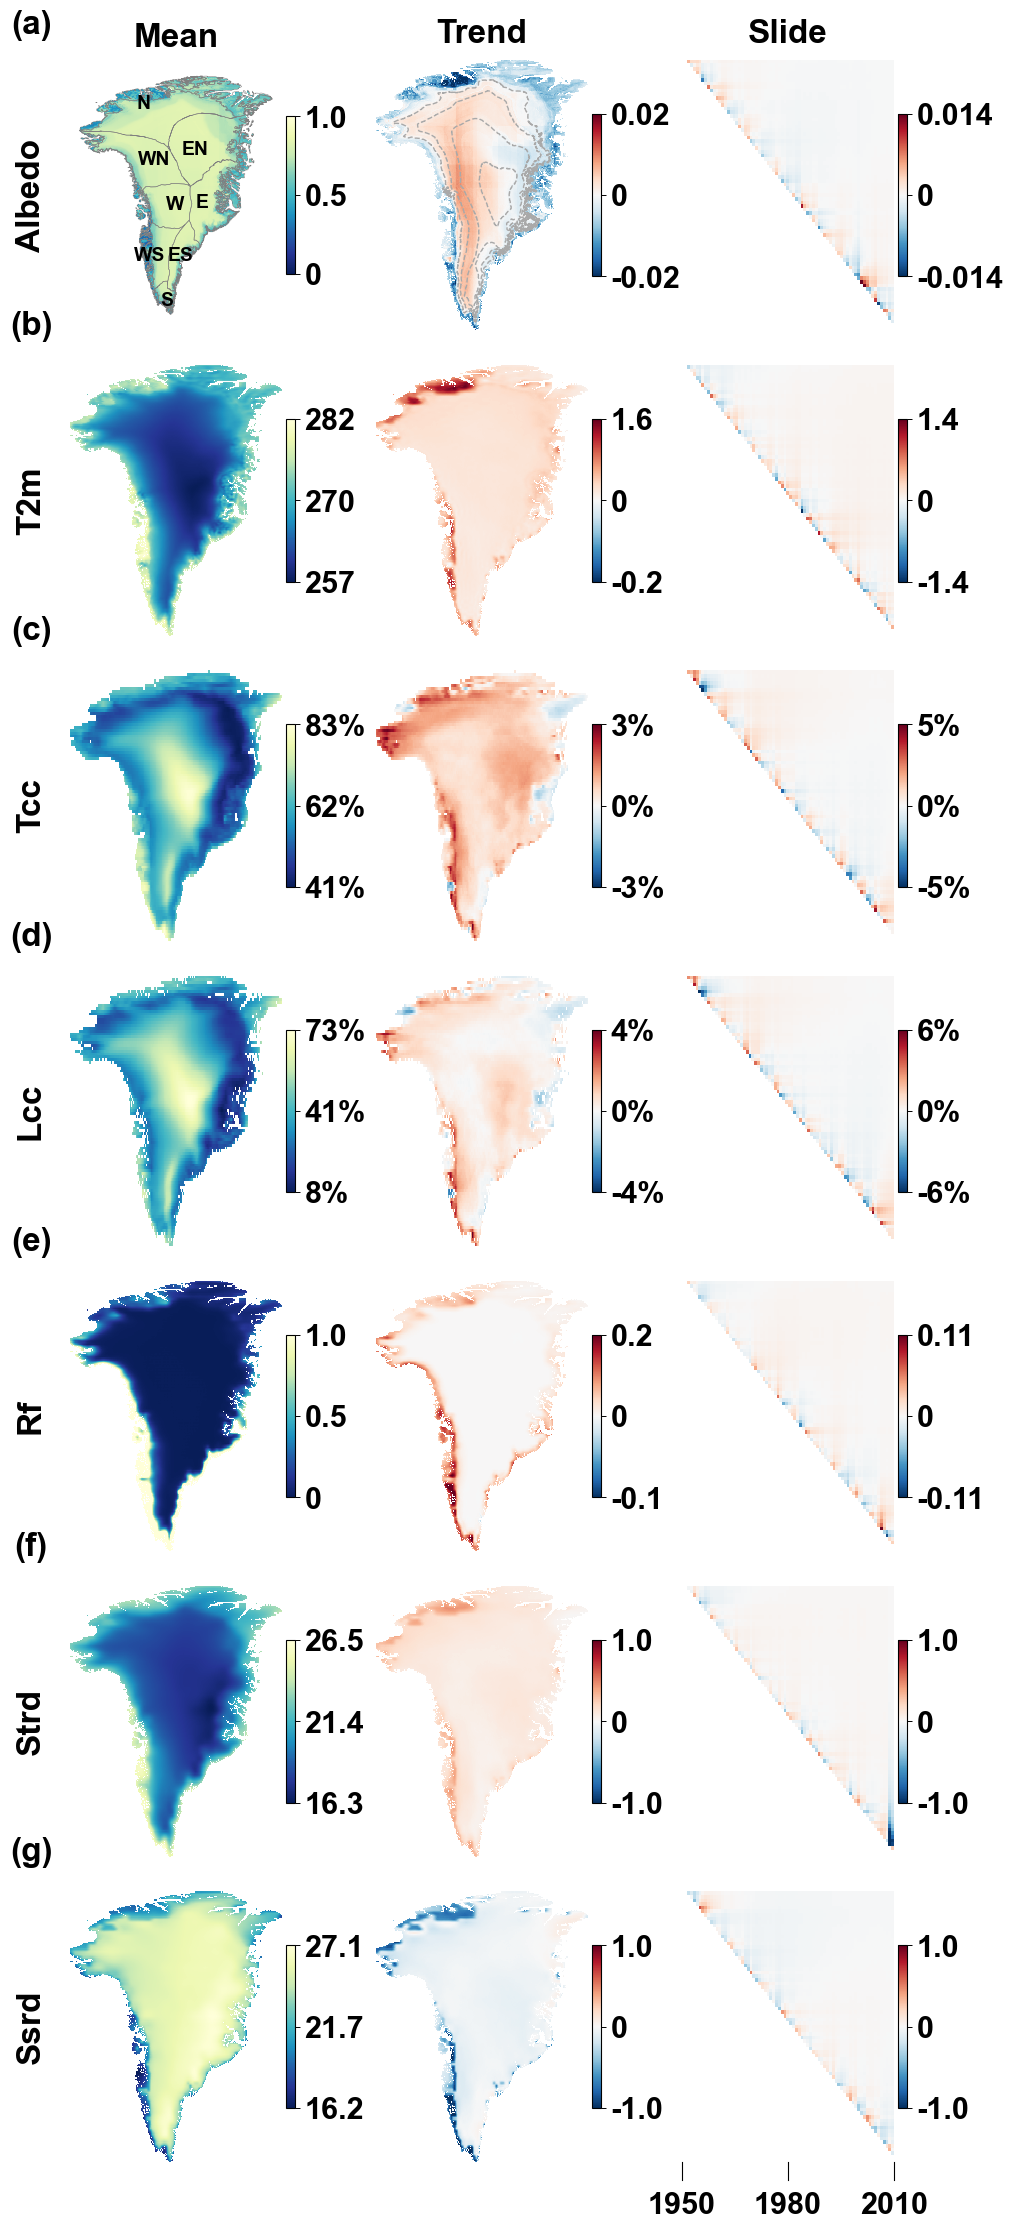

图像已保存：C:\greenland\1995bu\fig4\Fig4_npj_compact_v6.png


In [ ]:
# -*- coding: utf-8 -*-
"""
Greenland Climate Panel (npj Style: 紧凑版 + 大图 + 手动对齐)
--------------------------------
- 手动指定三列的 X 轴位置，实现 Mean 右移
- 增大子图宽度 w，显著减少空白
- 色标紧贴子图右侧
- 严格的行高对齐
- T2m Mean 色标改为整数显示
- Strd Slide 色标范围锁定为 -1 到 1
- [修改] 年份标签上移 + 手动添加三根短刻度线
"""

import os
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import LineString, MultiLineString
from matplotlib.colors import TwoSlopeNorm, Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.lines import Line2D  # [新增] 用于绘制刻度线

# ====================== 基础参数 ======================
FONT_SIZE = 22
TICK_FONT_SIZE = FONT_SIZE 
TITLE_SIZE = FONT_SIZE + 2

# [核心调整] 布局参数
FIG_WIDTH_INCHES = 8.5   
FIG_HEIGHT_PER_ROW = 3.3 

# 子图尺寸
SUBPLOT_W = 0.25  
COL_X_POS = [0.06, 0.42, 0.78] 

TOP_ALIGN = 0.96   
BOTTOM_MARGIN = 0.05
HSPACE_ABS = 0.015 

DATA_DIR = r"C:\greenland\1995bu\fig4"
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
})

# ====================== 加载数据 (保持不变) ======================
def load_basins():
    abbr_map = {
        "WestSouth": "WS", "WestNorth": "WN", "West": "W",
        "Melt": "M",
        "EastSouth": "ES", "EastNorth": "EN", "East": "E",
        "North": "N", "South": "S"
    }
    lst = []
    if not os.path.exists(BASIN_DIR):
        return gpd.GeoDataFrame()
    for fname in os.listdir(BASIN_DIR):
        if fname.lower().endswith(".shp"):
            gdf = gpd.read_file(os.path.join(BASIN_DIR, fname))
            gdf = gdf.to_crs("EPSG:4326")
            name = os.path.splitext(fname)[0]
            gdf["abbr"] = abbr_map.get(name, name)
            lst.append(gdf)
    if lst:
        return pd.concat(lst, ignore_index=True)
    return gpd.GeoDataFrame()

def load_contour():
    if not os.path.exists(CONTOUR_PATH):
        return gpd.GeoDataFrame()
    return gpd.read_file(CONTOUR_PATH).to_crs("EPSG:4326")

basins_all = load_basins()
contour_gdf = load_contour()

VARS_DESIRED = ["albedo", "t2m", "tcc", "lcc", "rf", "strd", "ssrd"]
DISPLAY = { "albedo": "Albedo", "t2m": "T2m", "tcc": "Tcc", "lcc": "Lcc", "rf": "Rf", "strd": "Strd", "ssrd": "Ssrd" }

VARS_PRESENT = []
if os.path.exists(DATA_DIR):
    for v in VARS_DESIRED:
        if os.path.exists(os.path.join(DATA_DIR, f"Greenland_{v}_MeanTrend.csv")):
            VARS_PRESENT.append(v)
else:
    sys.exit()

if not VARS_PRESENT: sys.exit()

# ====================== 工具函数 ======================
def make_grid(meantrend_csv):
    df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
    mean = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
    trend = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
    mean = mean.reindex(sorted(mean.columns), axis=1)
    trend = trend.reindex(sorted(trend.columns), axis=1)
    return mean, trend, mean.index.values.astype(float), mean.columns.values.astype(float)

def make_slide(slide_csv):
    df = pd.read_csv(slide_csv, index_col=0)
    vals = df.to_numpy(dtype=float)
    mask = np.tril(np.ones_like(vals, dtype=bool), -1)
    return np.ma.array(vals, mask=mask), df.index.astype(int), df.columns.astype(int)

def draw_contours(ax):
    if contour_gdf.empty: return
    for geom in contour_gdf.geometry:
        if isinstance(geom, LineString):
            xs, ys = geom.xy
            ax.plot(xs, ys, "darkgrey", linestyle="--", linewidth=1.0)
        elif isinstance(geom, MultiLineString):
            for p in geom.geoms:
                xs, ys = p.xy
                ax.plot(xs, ys, "darkgrey", linestyle="--", linewidth=1.0)

def draw_basins(ax):
    if basins_all.empty: return
    basins_all.boundary.plot(ax=ax, color="grey", linewidth=0.4, zorder=5)
    text_props = dict(fontsize=FONT_SIZE - 8, fontweight="bold", color="black", ha="center", va="center", zorder=10)
    for _, row in basins_all.iterrows():
        label = row["abbr"]
        if label == "M": continue
        pt = row.geometry.representative_point()
        x, y = pt.x, pt.y
        dx = dy = 0.0
        if label == "WS": dx = -3.3
        elif label == "WN": dx = 1.0
        elif label == "W": dx = 1.5
        elif label == "N": dy = 1.5
        elif label == "S": dy = -0.5
        elif label == "E": dx = -0.8
        elif label == "EN": dx = -1.0
        elif label == "ES": dx = 1
        ax.text(x + dx, y + dy, label, **text_props)

def draw_colorbar(fig, ax, im, var, col_name):
    cax = inset_axes(
        ax,
        width="4%",           
        height="60%",         
        loc="center left",    
        bbox_to_anchor=(1.02, 0., 1, 1), 
        bbox_transform=ax.transAxes,
        borderpad=0
    )

    cb = fig.colorbar(im, cax=cax)

    vmin = im.norm.vmin
    vmax = im.norm.vmax
    if hasattr(im.norm, "vcenter"):
        vc = im.norm.vcenter
    else:
        vc = 0.5 * (vmin + vmax)

    ticks = [vmin, vc, vmax]
    if abs(vmin) < 1e-9 and abs(vmax) < 1e-9: ticks = [0]
    
    cb.set_ticks(ticks)
    
    labels = []
    for v in ticks:
        if var == "t2m" and col_name == "Mean":
            labels.append(f"{int(round(v))}") 
        elif var in ["tcc", "lcc"]:
            labels.append(f"{v * 100:.0f}%")
        else:
            if abs(v) < 1e-3 and v != 0: s = f"{v:.1e}"
            elif abs(v) < 1: s = f"{v:.2g}"
            else: s = f"{v:.1f}"
            labels.append(s)
            
    cb.set_ticklabels(labels)
    cb.ax.tick_params(labelsize=TICK_FONT_SIZE)
    for lb in cb.ax.get_yticklabels():
        lb.set_fontweight("bold")

# ====================== 主绘图逻辑 ======================
n_rows = len(VARS_PRESENT)
COLS = ["Mean", "Trend", "Slide"]

FIG_HEIGHT = FIG_HEIGHT_PER_ROW * n_rows
fig = plt.figure(figsize=(FIG_WIDTH_INCHES, FIG_HEIGHT))

available_h = TOP_ALIGN - BOTTOM_MARGIN - (n_rows - 1) * HSPACE_ABS
h = available_h / n_rows

axes = []
row_first_axes = [None] * n_rows

for i, var in enumerate(VARS_PRESENT):
    mean_file = os.path.join(DATA_DIR, f"Greenland_{var}_MeanTrend.csv")
    slide_file = os.path.join(DATA_DIR, f"Greenland_{var}_SlidingTrend.csv")
    
    mean_grid, trend_grid, lats, lons = make_grid(mean_file)
    slide_vals, slide_rows, slide_cols = make_slide(slide_file)

    bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE_ABS

    for j, col in enumerate(COLS):
        left = COL_X_POS[j]
        ax = fig.add_axes([left, bottom, SUBPLOT_W, h])
        axes.append(ax)
        
        if j == 0: row_first_axes[i] = ax
        for sp in ax.spines.values(): sp.set_visible(False)

        # ===== 绘图 =====
        if col == "Mean":
            if var == "albedo": im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", norm=Normalize(vmin=0, vmax=1), shading="auto")
            elif var == "rf": im = ax.pcolormesh(lons, lats, mean_grid.values * 1e3, cmap="YlGnBu_r", norm=Normalize(vmin=0, vmax=1), shading="auto")
            elif var in ["strd", "ssrd"]: im = ax.pcolormesh(lons, lats, mean_grid.values / 1e6, cmap="YlGnBu_r", shading="auto")
            else: im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", shading="auto")
            if i == 0: draw_basins(ax)

        elif col == "Trend":
            if var == "albedo":
                norm = TwoSlopeNorm(vmin=-0.02, vcenter=0.0, vmax=0.02)
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r", norm=norm, shading="auto")
                draw_contours(ax)
            elif var == "t2m": im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-0.2, vcenter=0.0, vmax=1.6), shading="auto")
            elif var == "rf": im = ax.pcolormesh(lons, lats, trend_grid.values * 1e3, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-0.1, vcenter=0.0, vmax=0.2), shading="auto")
            elif var in ["strd", "ssrd"]: im = ax.pcolormesh(lons, lats, trend_grid.values / 1e6, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1), shading="auto")
            else:
                data = trend_grid.values
                vabs = np.nanmax(np.abs(data)) if np.any(np.isfinite(data)) else 1.0
                if vabs == 0: vabs = 1.0
                im = ax.pcolormesh(lons, lats, data, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-vabs, vcenter=0.0, vmax=vabs), shading="auto")

        else:  # Slide
            if var == "rf": vals = slide_vals * 1e3
            elif var in ["strd", "ssrd"]: vals = slide_vals / 1e6
            else: vals = slide_vals
            
            vabs = np.nanmax(np.abs(vals)) if vals.size > 0 else 1.0
            if vabs == 0 or not np.isfinite(vabs): vabs = 1.0
            
            if var == "strd":
                norm = TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1)
            elif var == "ssrd" and vabs < 1: 
                norm = TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1)
            else: 
                norm = TwoSlopeNorm(vmin=-vabs, vcenter=0.0, vmax=vabs)

            im = ax.pcolormesh(slide_cols, slide_rows, vals, cmap="RdBu_r", norm=norm, shading="auto")
            ax.invert_yaxis()

        draw_colorbar(fig, ax, im, var, col)
        ax.set_xticks([])
        ax.set_yticks([])

        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=12)

# ====================== 标签绘制 ======================
x_label_pos = 0.015 
for i, var in enumerate(VARS_PRESENT):
    ax0 = row_first_axes[i]
    if ax0 is None: continue
    
    pos = ax0.get_position()
    y_mid = pos.y0 + pos.height / 2.0
    y_top = pos.y1 + 0.01

    fig.text(
        x_label_pos, y_mid, DISPLAY[var],
        fontsize=TITLE_SIZE, fontweight="bold",
        rotation=90, ha="center", va="center"
    )
    fig.text(
        x_label_pos, y_top, f"({chr(97 + i)})",
        fontsize=TITLE_SIZE, fontweight="bold",
        ha="center", va="bottom"
    )

# ====================== 年份刻度与标签 (手动绘制) ======================
if axes:
    last_ax = axes[-1]
    
    # 获取最后一个子图的位置信息
    bbox = last_ax.get_position()
    x0, y0 = bbox.x0, bbox.y0
    w = bbox.width
    
    # 设置刻度参数
    tick_len = 0.008       # 刻度线长度 (Figure 坐标系)
    text_pad = 0.005       # 文字与刻度下端的距离
    
    # 定义三个刻度的位置: 左边、中间、右边
    tick_x_list = [x0, x0 + w/2, x0 + w]
    tick_labels = ["1950", "1980", "2010"]
    
    # 绘制
    for tx, label in zip(tick_x_list, tick_labels):
        # 1. 绘制刻度线 (Line2D)
        # xdata=[tx, tx], ydata=[y0, y0 - tick_len]
        line = Line2D(
            [tx, tx], [y0, y0 - tick_len],
            transform=fig.transFigure, # 使用 Figure 坐标系，绝对定位
            color="black", 
            linewidth=0.8, # 与 axes.linewidth 保持一致
            linestyle="-"
        )
        fig.add_artist(line)
        
        # 2. 绘制文字 (居中对齐于刻度)
        fig.text(
            tx, 
            y0 - tick_len - text_pad, 
            label, 
            fontsize=TICK_FONT_SIZE, 
            fontweight="bold", 
            ha="center", # 居中对齐
            va="top"     # 顶部对齐 (紧贴刻度)
        )

SAVE_PATH = os.path.join(DATA_DIR, f"Fig4_npj_compact_v6.png")
plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()
print(f"图像已保存：{SAVE_PATH}")

[trend_per_decade] min=-0.012143, median=0.223767, max=1.587689


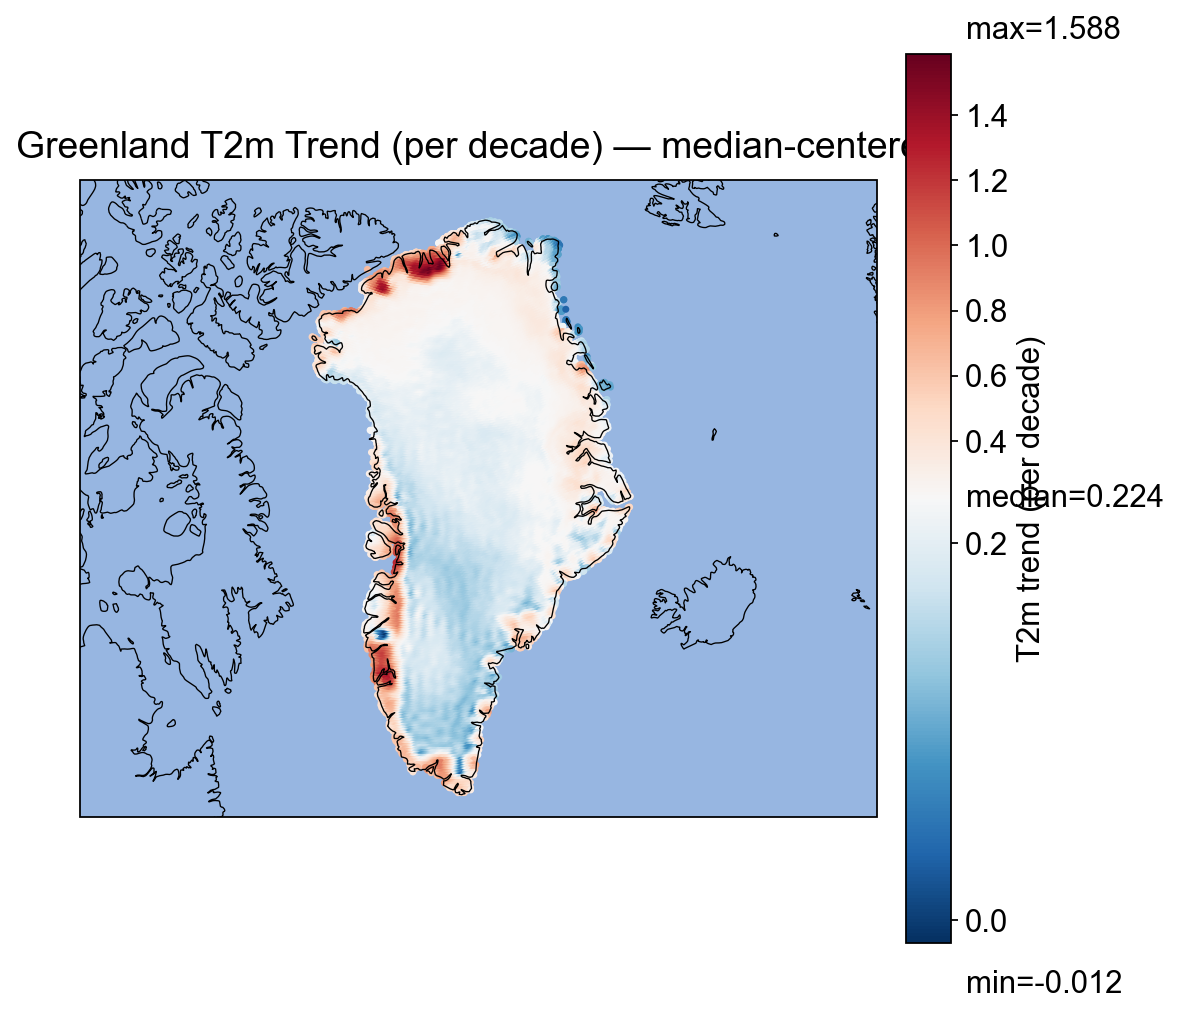

In [ ]:
# -*- coding: utf-8 -*-
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ================== path ==================
csv_path = r"C:\greenland\1995bu\fig4\Greenland_t2m_MeanTrend.csv"

# ================== load ==================
df = pd.read_csv(csv_path)

# 必需列
for c in ["lat", "lon", "trend_per_decade"]:
    if c not in df.columns:
        raise ValueError(f"CSV 缺少列: {c}。现有列：{list(df.columns)}")

df = df[["lat", "lon", "trend_per_decade"]].dropna().rename(columns={"trend_per_decade": "trend"})
df["lon"] = ((df["lon"] + 180) % 360) - 180  # 若是0-360自动转为-180~180

trend = df["trend"].to_numpy()
vmin = float(np.nanmin(trend))
vmax = float(np.nanmax(trend))
vcenter = float(np.nanmedian(trend))  # 你要的：中位数当白色

# TwoSlopeNorm 需要 vmin < vcenter < vmax，做稳健处理
eps = 1e-12
if not (vmin + eps < vcenter < vmax - eps):
    # 如果中位数贴边/数据几乎常数，就退化为用均值或0做中心
    alt_center = float(np.nanmean(trend))
    if vmin + eps < alt_center < vmax - eps:
        vcenter = alt_center
    else:
        # 还是不行：强行把中心挤进区间
        vcenter = (vmin + vmax) / 2.0

norm = TwoSlopeNorm(vmin=vmin, vcenter=vcenter, vmax=vmax)

# ================== colorbar ticks every 0.2 ==================
step = 0.2
start = np.floor(vmin / step) * step
end   = np.ceil(vmax / step) * step
ticks = np.round(np.arange(start, end + step * 0.5, step), 10)

# ================== decide grid vs scatter ==================
lats = np.sort(df["lat"].unique())
lons = np.sort(df["lon"].unique())
is_grid = (len(lats) * len(lons) == len(df))

# ================== plot ==================
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 14

proj = ccrs.NorthPolarStereo(central_longitude=-45)
data_crs = ccrs.PlateCarree()

fig = plt.figure(figsize=(7.2, 7.2), dpi=160)
ax = plt.axes(projection=proj)

# 自适应范围（按数据）
lon_min, lon_max = df["lon"].min(), df["lon"].max()
lat_min, lat_max = df["lat"].min(), df["lat"].max()
ax.set_extent([lon_min - 2, lon_max + 2, lat_min - 1, lat_max + 1], crs=data_crs)

ax.add_feature(cfeature.LAND, zorder=0)
ax.add_feature(cfeature.OCEAN, zorder=0)
ax.coastlines(linewidth=0.6)

mappable = None
if is_grid:
    grid = df.pivot(index="lat", columns="lon", values="trend").reindex(index=lats, columns=lons)
    Z = grid.to_numpy()
    Lon2, Lat2 = np.meshgrid(lons, lats)
    mappable = ax.pcolormesh(
        Lon2, Lat2, Z,
        transform=data_crs,
        cmap="RdBu_r",
        norm=norm,
        shading="auto",
        rasterized=True
    )
else:
    mappable = ax.scatter(
        df["lon"].to_numpy(), df["lat"].to_numpy(),
        c=df["trend"].to_numpy(),
        s=10,
        cmap="RdBu_r",
        norm=norm,
        transform=data_crs,
        linewidths=0,
        rasterized=True
    )

cb = plt.colorbar(mappable, ax=ax, orientation="vertical", shrink=0.82, pad=0.03, ticks=ticks)
cb.set_label("T2m trend (per decade)")
cb.ax.tick_params(length=3)

# 在色标旁明确标出 min/max（你要“显示最大最小值”）
cb.ax.text(1.35, 1.01, f"max={vmax:.3f}", transform=cb.ax.transAxes, ha="left", va="bottom")
cb.ax.text(1.35, -0.03, f"min={vmin:.3f}", transform=cb.ax.transAxes, ha="left", va="top")
cb.ax.text(1.35, 0.50, f"median={vcenter:.3f}", transform=cb.ax.transAxes, ha="left", va="center")

ax.set_title("Greenland T2m Trend (per decade) — median-centered", pad=10)

# ================== print stats + show (no save) ==================
print(f"[trend_per_decade] min={vmin:.6f}, median={vcenter:.6f}, max={vmax:.6f}")
plt.tight_layout()
plt.show()


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


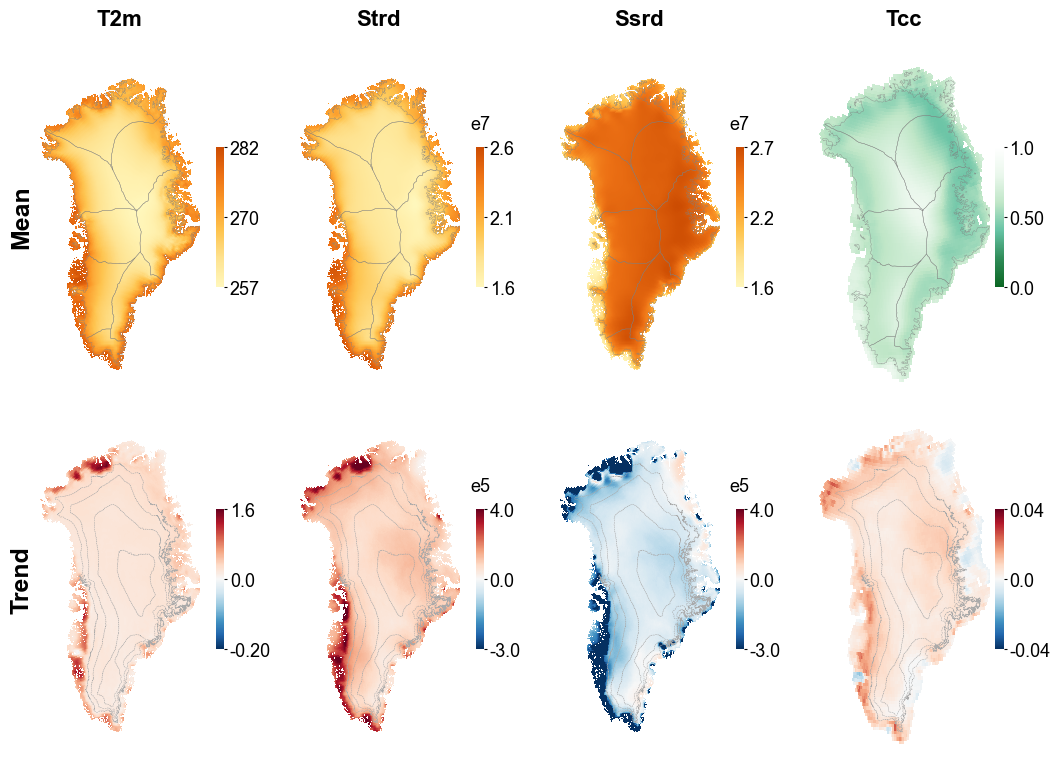

✅ 图片已保存至: C:\greenland\1995bu\fig4\Fig4_Final_V2.png


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm, LinearSegmentedColormap
import cartopy.crs as ccrs
import geopandas as gpd

# ================= 1. 基本参数（严格执行字号） =================
BASE_FONT = 18           
TITLE_SIZE = 16          
TICK_FONT_SIZE = 13      
LABEL_FONT_SIZE = 18     
BASIN_LABEL_SIZE = 11    # 流域标识字号

# 【布局参数：极致紧凑优化】
FIG_WIDTH = 10.5         
FIG_HEIGHT = 8.0         
HSPACE = 0.015           
WSPACE = 0.07            
LEFT_MARGIN = 0.04       
RIGHT_MARGIN = 0.96      
TOP_ALIGN = 0.94
BOTTOM_MARGIN = 0.05

DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = os.path.join(DATA_DIR, "Fig4_Final_V2.png")

# 流域和等高线路径
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

PROJ = ccrs.NorthPolarStereo(central_longitude=-45)
DATA_CRS = ccrs.PlateCarree()

plt.rcParams.update({
    "font.family": "Arial",
    "axes.linewidth": 0.8
})

# ================= 2. 自定义 Colormaps =================
cmap_tcc_green = LinearSegmentedColormap.from_list("tcc_green", ["#0B6623", "#2E8B57", "#66C2A4", "#BFE6C7", "#EAF7EC", "#FFFFFF"])
cmap_yellow_orange = LinearSegmentedColormap.from_list("yellow_orange", ["#FFF7BC", "#FEE391", "#FEC44F", "#FB9A29", "#EC7014", "#CC4C02"])

ROW_NAMES = ["mean", "trend"]
VARS = ["t2m", "strd", "ssrd", "tcc"]

# ================= 3. 流域名称映射 =================
BASIN_NAME_MAP = {
    "northwest": "NW", "southwest": "SW", "northeast": "NE", "southeast": "SE",
    "westnorth": "NW", "westsouth": "SW", "eastnorth": "NE", "eastsouth": "SE",
    "northwes": "NW", "southwes": "SW", "northeas": "NE", "southeas": "SE",
    "west": "W", "east": "E", "north": "N", "south": "S", "middle": "M",
    "nw": "NW", "sw": "SW", "ne": "NE", "se": "SE", "w": "W", "e": "E", "n": "N", "s": "S", "m": "M"
}

# 只保留这 8 个流域缩写
VALID_ABBR = {"NW", "NE", "SW", "SE", "W", "E", "N", "S"}

# ================= 4. 预加载流域和等高线数据 =================
basins_all = []
if os.path.exists(BASIN_DIR):
    for f in os.listdir(BASIN_DIR):
        if f.endswith(".shp"):
            gdf = gpd.read_file(os.path.join(BASIN_DIR, f)).to_crs("EPSG:4326")
            basin_name = f.split('.')[0].lower()
            mapped_abbr = BASIN_NAME_MAP.get(basin_name, basin_name.upper()[:2])
            gdf["abbr"] = mapped_abbr
            basins_all.append(gdf)

basins_gdf = pd.concat(basins_all, ignore_index=True) if basins_all else gpd.GeoDataFrame()
# 只保留有效流域
basins_gdf = basins_gdf[basins_gdf["abbr"].isin(VALID_ABBR)] if not basins_gdf.empty else basins_gdf

contour_gdf = None
if os.path.exists(CONTOUR_PATH):
    contour_gdf = gpd.read_file(CONTOUR_PATH).to_crs("EPSG:4326")

# ================= 5. 辅助函数 =================
def draw_basins(ax, basins_gdf):
    """绘制流域分界线（不含标识）"""
    if basins_gdf.empty:
        return
    
    # 绘制流域边界线（线宽减半）
    ax.add_geometries(
        basins_gdf.geometry, crs=DATA_CRS, edgecolor="grey",
        facecolor="none", linewidth=0.25, zorder=6
    )

def draw_contour(ax, contour_gdf):
    """绘制等高线"""
    if contour_gdf is not None and not contour_gdf.empty:
        ax.add_geometries(
            contour_gdf.geometry, crs=DATA_CRS, 
            edgecolor="darkgrey", facecolor='none',
            linestyle="--", linewidth=0.35, zorder=6
        )

def fmt(v):
    """格式化色标刻度"""
    if abs(v) < 1e-12: return "0.0"
    if abs(v) >= 10: return f"{v:.0f}"
    if abs(v) >= 1: return f"{v:.1f}"
    if abs(v) >= 0.01: return f"{v:.2f}"
    return f"{v:.1e}"

# ================= 6. 布局计算 =================
n_rows = len(ROW_NAMES)
n_cols = len(VARS)
fig = plt.figure(figsize=(FIG_WIDTH, FIG_HEIGHT))

slot_w = (RIGHT_MARGIN - LEFT_MARGIN - (n_cols-1)*WSPACE) / n_cols
cb_w = 0.008             
h = (TOP_ALIGN - BOTTOM_MARGIN - (n_rows-1)*HSPACE) / n_rows

EXTENT = [-680000, 850000, -3400000, -600000]

# ================= 7. 主循环 =================
for i, row_name in enumerate(ROW_NAMES):
    for j, var in enumerate(VARS):
        left = LEFT_MARGIN + j * (slot_w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        
        # 地图与色标的间隙
        current_cb_gap = 0.015 if j < 3 else 0.005
        map_w = slot_w - cb_w - current_cb_gap

        # 创建地图轴
        ax = fig.add_axes([left, bottom, map_w, h], projection=PROJ)
        ax.set_extent(EXTENT, crs=PROJ)
        ax.set_aspect('equal', adjustable='datalim')
        for s in ax.spines.values(): s.set_visible(False)

        # 加载数据
        csv_path = os.path.join(DATA_DIR, f"Greenland_{var}_MeanTrend.csv")
        if not os.path.exists(csv_path): continue
        df = pd.read_csv(csv_path).dropna(subset=["mean", "trend_per_decade"])
        
        mean_grid = df.pivot(index="lat", columns="lon", values="mean").sort_index()
        trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index()
        lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
        lon_b = np.concatenate([lons - 0.05, [lons[-1] + 0.05]])
        lat_b = np.concatenate([lats - 0.05, [lats[-1] + 0.05]])

        e_label = ""
        if row_name.lower() == "mean":
            data = mean_grid.values
            if var in ["strd", "ssrd"]:
                data /= 1e7
                e_label = "e7"
            cmap = cmap_tcc_green if var == "tcc" else cmap_yellow_orange
            vmin, vmax = (0.0, 1.0) if var == "tcc" else (np.nanmin(data), np.nanmax(data))
            norm = Normalize(vmin, vmax)
            ticks = [vmin, (vmin + vmax) / 2, vmax]
        else:
            data = trend_grid.values
            if var in ["strd", "ssrd"]:
                data /= 1e5
                e_label = "e5"
            cmap = "RdBu_r"
            if var == "t2m": norm = TwoSlopeNorm(vmin=-0.2, vcenter=0.0, vmax=1.6)
            elif var == "tcc": norm = TwoSlopeNorm(vmin=-0.04, vcenter=0.0, vmax=0.04)
            elif var in ["strd", "ssrd"]: norm = TwoSlopeNorm(vmin=-3, vcenter=0.0, vmax=4)
            else: norm = TwoSlopeNorm(vmin=np.nanmin(data), vcenter=0.0, vmax=np.nanmax(data))
            ticks = [norm.vmin, 0.0, norm.vmax]

        # 绘制数据
        im = ax.pcolormesh(lon_b, lat_b, data, transform=DATA_CRS, cmap=cmap, norm=norm, 
                          shading="auto", rasterized=True, zorder=3)

        # ===== 添加流域和等高线 =====
        if row_name.lower() == "mean":
            # Mean 行：所有子图都加流域分界线（不含字母）
            draw_basins(ax, basins_gdf)
        else:
            # Trend 行：所有子图都加等高线
            draw_contour(ax, contour_gdf)

        # 创建独立色标轴
        cb_left = left + map_w + current_cb_gap
        cb_h_ratio = 0.40
        cb_bottom = bottom + (h * (1 - cb_h_ratio) / 2)
        cb_ax = fig.add_axes([cb_left, cb_bottom, cb_w, h * cb_h_ratio])

        cb = fig.colorbar(im, cax=cb_ax, ticks=ticks)
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=TICK_FONT_SIZE, length=2, pad=2)
        cb.ax.yaxis.set_ticks_position("right")
        cb.set_ticklabels([fmt(v) for v in ticks])

        # 科学计数法标签
        if e_label:
            cb_ax.text(0.5, 1.1, e_label, transform=cb_ax.transAxes, 
                       fontsize=TICK_FONT_SIZE, ha="center", va="bottom")

        # 标题处理（首字母大写）
        if i == 0:
            ax.set_title(var.capitalize(), fontsize=TITLE_SIZE, fontweight="bold", pad=12)
        if j == 0:
            ax.text(-0.03, 0.5, row_name.capitalize(), transform=ax.transAxes, 
                    fontsize=LABEL_FONT_SIZE, fontweight="bold", rotation=90, ha="right", va="center")

# ================= 8. 保存 =================
plt.savefig(SAVE_PATH, dpi=400, bbox_inches="tight")
plt.show()
print(f"✅ 图片已保存至: {SAVE_PATH}")

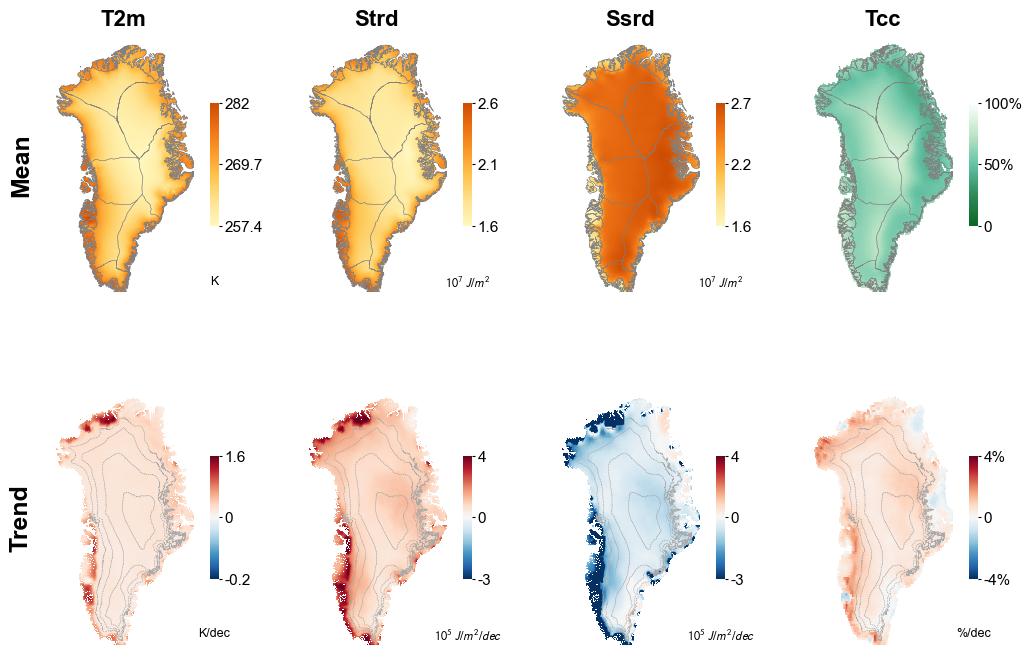

✅ 极致压缩版图片已保存: C:\greenland\1995bu\fig4\Fig4_Compact_ThinCB.png


In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm, LinearSegmentedColormap
import cartopy.crs as ccrs
import geopandas as gpd

# ================= 1. 环境与字体全局配置 =================
plt.rcParams.update({
    "font.family": "Arial",
    "mathtext.fontset": "stixsans", 
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42
})

BASE_FONT, TITLE_SIZE, TICK_FONT_SIZE, LABEL_FONT_SIZE = 18, 16, 11, 18

# 【布局参数：极致紧凑优化】
FIG_WIDTH, FIG_HEIGHT = 11, 8.0  # 稍微压低高度使布局更扁平紧凑
HSPACE = 0.002                   # 行间距缩小
WSPACE = 0.08                    
LEFT_MARGIN, RIGHT_MARGIN = 0.08, 0.92
TOP_ALIGN, BOTTOM_MARGIN = 0.94, 0.06

DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = os.path.join(DATA_DIR, "Fig4_Compact_ThinCB.png")
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

PROJ = ccrs.NorthPolarStereo(central_longitude=-45)
DATA_CRS = ccrs.PlateCarree()

# ================= 2. 变量与单位 =================
VARS = ["t2m", "strd", "ssrd", "tcc"]
VAR_TITLES = {"t2m": "T2m", "strd": "Strd", "ssrd": "Ssrd", "tcc": "Tcc"}

UNITS = {
    "mean": {
        "t2m": r"K",
        "strd": r"$10^{7}\ J/m^{2}$",
        "ssrd": r"$10^{7}\ J/m^{2}$",
        "tcc": "" 
    },
    "trend": {
        "t2m": r"K/dec",
        "strd": r"$10^{5}\ J/m^{2}/dec$",
        "ssrd": r"$10^{5}\ J/m^{2}/dec$",
        "tcc": r"%/dec"
    }
}

cmap_tcc_green = LinearSegmentedColormap.from_list("tcc_green", ["#0B6623", "#2E8B57", "#66C2A4", "#BFE6C7", "#FFFFFF"])
cmap_yellow_orange = LinearSegmentedColormap.from_list("yellow_orange", ["#FFF7BC", "#FEE391", "#FEC44F", "#FB9A29", "#EC7014", "#CC4C02"])

# ================= 3. 绘图主循环 =================
fig = plt.figure(figsize=(FIG_WIDTH, FIG_HEIGHT))
ROW_NAMES = ["mean", "trend"]
n_rows, n_cols = len(ROW_NAMES), len(VARS)

# 动态计算子图尺寸
slot_w = (RIGHT_MARGIN - LEFT_MARGIN - (n_cols-1)*WSPACE) / n_cols
h = (TOP_ALIGN - BOTTOM_MARGIN - (n_rows-1)*HSPACE) / n_rows
EXTENT = [-680000, 850000, -3400000, -600000]

# 加载矢量数据
basins_gdf = None
if os.path.exists(BASIN_DIR):
    basins_all = [gpd.read_file(os.path.join(BASIN_DIR, f)).to_crs("EPSG:4326") 
                  for f in os.listdir(BASIN_DIR) if f.endswith(".shp")]
    if basins_all: basins_gdf = pd.concat(basins_all)
contour_gdf = gpd.read_file(CONTOUR_PATH).to_crs("EPSG:4326") if os.path.exists(CONTOUR_PATH) else None

for i, row_name in enumerate(ROW_NAMES):
    for j, var in enumerate(VARS):
        left = LEFT_MARGIN + j * (slot_w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        
        # 色标宽度调细 (0.008)
        cb_w, cb_gap = 0.008, 0.015
        map_w = slot_w - cb_w - cb_gap

        ax = fig.add_axes([left, bottom, map_w, h], projection=PROJ)
        ax.set_extent(EXTENT, crs=PROJ)
        ax.axis('off')

        # 数据读取与转换
        csv_path = os.path.join(DATA_DIR, f"Greenland_{var}_MeanTrend.csv")
        if not os.path.exists(csv_path): continue
        df = pd.read_csv(csv_path)
        
        val_col = "mean" if row_name == "mean" else "trend_per_decade"
        if var == "tcc": df[val_col] *= 100
        if var in ["strd", "ssrd"]: 
            df[val_col] /= (1e7 if row_name == "mean" else 1e5)

        grid = df.pivot(index="lat", columns="lon", values=val_col).sort_index()
        
        # 归一化逻辑
        if row_name == "mean":
            cmap = cmap_tcc_green if var == "tcc" else cmap_yellow_orange
            vmin, vmax = (0, 100) if var == "tcc" else (np.nanmin(grid.values), np.nanmax(grid.values))
            norm = Normalize(vmin, vmax)
            ticks = [vmin, (vmin + vmax) / 2, vmax]
        else:
            cmap = "RdBu_r"
            if var == "t2m": norm = TwoSlopeNorm(vmin=-0.2, vcenter=0.0, vmax=1.6)
            elif var == "tcc": norm = TwoSlopeNorm(vmin=-4.0, vcenter=0.0, vmax=4.0)
            elif var in ["strd", "ssrd"]: norm = TwoSlopeNorm(vmin=-3.0, vcenter=0.0, vmax=4.0)
            else: norm = TwoSlopeNorm(vmin=np.nanmin(grid.values), vcenter=0.0, vmax=np.nanmax(grid.values))
            ticks = [norm.vmin, 0.0, norm.vmax]

        # 绘图
        im = ax.pcolormesh(grid.columns, grid.index, grid.values, transform=DATA_CRS, 
                           cmap=cmap, norm=norm, shading="auto", rasterized=True, zorder=3)
        
        if row_name == "mean" and basins_gdf is not None:
            ax.add_geometries(basins_gdf.geometry, crs=DATA_CRS, edgecolor="grey", facecolor="none", linewidth=0.3, zorder=6)
        if row_name == "trend" and contour_gdf is not None:
            ax.add_geometries(contour_gdf.geometry, crs=DATA_CRS, edgecolor="darkgrey", facecolor='none', linestyle="--", linewidth=0.4, zorder=6)

        # 色标 (调细，垂直居中)
        cb_h = h * 0.35 
        cb_bottom = bottom + (h - cb_h) / 2
        cb_ax = fig.add_axes([left + map_w + cb_gap, cb_bottom, cb_w, cb_h])
        cb = fig.colorbar(im, cax=cb_ax, ticks=ticks)
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=TICK_FONT_SIZE, length=2, pad=2)

        # 刻度标签格式化 (强制中间为0)
        tick_labels = []
        for v in ticks:
            if abs(v) < 1e-7: label = "0"
            elif var == "tcc": label = f"{v:.0f}%" if abs(v) >= 1 else f"{v:.1f}%"
            else: label = f"{v:.1f}".rstrip('0').rstrip('.') if abs(v) > 0.01 else f"{v:.1e}"
            tick_labels.append(label)
        cb.ax.set_yticklabels(tick_labels)

        # 单位位置 (色标正下方)
        unit_text = UNITS[row_name][var]
        cb_ax.text(0.5, -0.4, unit_text, transform=cb_ax.transAxes, 
                   fontsize=TICK_FONT_SIZE - 2, ha="center", va="top")

        # 标题与行名
        if i == 0:
            ax.set_title(VAR_TITLES[var], fontsize=TITLE_SIZE, fontweight="bold", pad=8)
        if j == 0:
            ax.text(-0.15, 0.5, row_name.capitalize(), transform=ax.transAxes, 
                    fontsize=LABEL_FONT_SIZE, fontweight="bold", rotation=90, ha="right", va="center")

plt.savefig(SAVE_PATH, dpi=400, bbox_inches="tight")
plt.show()
print(f"✅ 极致压缩版图片已保存: {SAVE_PATH}")

In [2]:
import xarray as xr
import numpy as np
import pandas as pd
import os

# ================= 1. 读取NC文件 =================
nc_path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5_1950_2024_4_9_ForcedTime.nc"

print("=" * 80)
print("📂 读取 NC 文件...")
print(f"文件路径: {nc_path}")
print("=" * 80)

# 打开数据集
ds = xr.open_dataset(nc_path)

# ================= 2. 查看文件基本信息 =================
print("\n📊 数据集基本信息:")
print("-" * 80)
print(ds)
print("-" * 80)

# ================= 3. 查看变量列表 =================
print("\n📋 所有变量列表:")
print("-" * 80)
for var in ds.data_vars:
    print(f"  ✓ {var}")
print("-" * 80)

# ================= 4. 检查关键变量 =================
required_vars = ['ssrd', 'albedo', 'str']
print("\n🔍 检查关键变量:")
print("-" * 80)

available_vars = {}
for var in required_vars:
    if var in ds.data_vars:
        print(f"  ✅ {var:10s} - 存在")
        available_vars[var] = ds[var]
        
        # 显示变量详细信息
        print(f"      维度: {ds[var].dims}")
        print(f"      形状: {ds[var].shape}")
        print(f"      单位: {ds[var].attrs.get('units', 'N/A')}")
        print(f"      长名: {ds[var].attrs.get('long_name', 'N/A')}")
        print()
    else:
        print(f"  ❌ {var:10s} - 缺失")
        print()

# ================= 5. 检查时间维度 =================
print("\n📅 时间维度信息:")
print("-" * 80)
if 'time' in ds.dims:
    time_var = ds['time']
    print(f"  时间范围: {time_var.values[0]} 至 {time_var.values[-1]}")
    print(f"  时间步数: {len(time_var)}")
    print(f"  时间间隔: {time_var.attrs.get('long_name', 'N/A')}")
    
    # 检查是否是月均值
    time_diff = pd.to_datetime(time_var.values[1]) - pd.to_datetime(time_var.values[0])
    print(f"  时间间隔: {time_diff.days} 天")
    if 28 <= time_diff.days <= 31:
        print(f"  ✅ 确认为月均值数据")
    else:
        print(f"  ⚠️  可能不是月均值数据")
else:
    print("  ❌ 未找到 'time' 维度")
print("-" * 80)

# ================= 6. 检查空间维度 =================
print("\n🌍 空间维度信息:")
print("-" * 80)
for dim in ['latitude', 'lat', 'longitude', 'lon', 'x', 'y']:
    if dim in ds.dims:
        print(f"  ✓ {dim}: {ds.dims[dim]} 个格点")
        if dim in ds.coords:
            coord = ds.coords[dim]
            print(f"    范围: {coord.values.min():.4f} 至 {coord.values.max():.4f}")
print("-" * 80)

# ================= 7. 数据值范围检查 =================
print("\n📊 数据值范围检查:")
print("-" * 80)

for var_name, var_data in available_vars.items():
    print(f"\n  变量: {var_name}")
    
    # 计算统计量
    values = var_data.values
    print(f"    最小值: {np.nanmin(values):.6e}")
    print(f"    最大值: {np.nanmax(values):.6e}")
    print(f"    平均值: {np.nanmean(values):.6e}")
    print(f"    NaN数量: {np.sum(np.isnan(values))} / {values.size} ({np.sum(np.isnan(values))/values.size*100:.2f}%)")
    
    # 检查合理性
    if var_name == 'albedo':
        if np.nanmin(values) >= 0 and np.nanmax(values) <= 1:
            print(f"    ✅ 反照率范围正常 [0, 1]")
        else:
            print(f"    ⚠️  反照率范围异常！应在 [0, 1]")
    
    if var_name == 'ssrd':
        if np.nanmin(values) >= 0:
            print(f"    ✅ SSRD为正值（符合物理意义）")
        else:
            print(f"    ⚠️  SSRD存在负值（异常）")
    
    if var_name == 'str':
        print(f"    ℹ️  STR可以为负值（冰盖净失去长波辐射）")

print("-" * 80)

# ================= 8. 测试计算净辐射 =================
print("\n🧮 测试计算净辐射:")
print("-" * 80)

if all(var in ds.data_vars for var in required_vars):
    print("  ✅ 所有变量齐全，可以计算净辐射")
    
    # 测试计算第一个时间步
    ssrd_test = ds['ssrd'].isel(time=0).values
    albedo_test = ds['albedo'].isel(time=0).values
    str_test = ds['str'].isel(time=0).values
    
    # 计算净辐射
    net_sw = ssrd_test * (1 - albedo_test)  # 净短波
    net_rad = net_sw + str_test              # 总净辐射
    
    print(f"\n  测试计算（第一个时间步）:")
    print(f"    净短波范围: {np.nanmin(net_sw):.2e} 至 {np.nanmax(net_sw):.2e}")
    print(f"    总净辐射范围: {np.nanmin(net_rad):.2e} 至 {np.nanmax(net_rad):.2e}")
    
    # 检查单位
    ssrd_unit = ds['ssrd'].attrs.get('units', 'unknown')
    str_unit = ds['str'].attrs.get('units', 'unknown')
    
    print(f"\n  ⚠️  请检查单位一致性:")
    print(f"    SSRD单位: {ssrd_unit}")
    print(f"    STR单位:  {str_unit}")
    
    if ssrd_unit == str_unit:
        print(f"    ✅ 单位一致，可以直接相加")
    else:
        print(f"    ⚠️  单位可能不一致，需要转换！")
    
else:
    missing = [v for v in required_vars if v not in ds.data_vars]
    print(f"  ❌ 缺少变量: {missing}")
    print(f"  无法计算净辐射")

print("-" * 80)

# ================= 9. 趋势计算可行性 =================
print("\n📈 趋势计算可行性评估:")
print("-" * 80)

if 'time' in ds.dims and len(ds['time']) > 0:
    n_years = len(ds['time']) / 12  # 假设月均值
    print(f"  数据年数: {n_years:.1f} 年")
    
    if n_years >= 10:
        print(f"  ✅ 数据长度足够进行趋势分析（建议 ≥10年）")
    else:
        print(f"  ⚠️  数据年数较短，趋势可能不稳定")
    
    print(f"\n  可用方法:")
    print(f"    1. 线性回归（scipy.stats.linregress）")
    print(f"    2. Sen斜率（scipy.stats.theilslopes）")
    print(f"    3. Mann-Kendall检验（pymannkendall）")
else:
    print(f"  ❌ 时间维度异常，无法计算趋势")

print("-" * 80)

# ================= 10. 总结 =================
print("\n" + "=" * 80)
print("📝 总结与建议:")
print("=" * 80)

if all(var in ds.data_vars for var in required_vars):
    print("✅ 文件包含所有必需变量 (ssrd, albedo, str)")
    print("✅ 可以计算: 净辐射 = SSRD × (1 - albedo) + STR")
    print("\n下一步:")
    print("  1. 确认单位是否一致（J/m² 或 W/m²）")
    print("  2. 计算每个格点的时间序列均值")
    print("  3. 使用线性回归计算趋势（/decade）")
    print("  4. 导出为CSV或绘图")
else:
    print("❌ 文件缺少必需变量，无法进行计算")

print("=" * 80)

# 关闭数据集
ds.close()

📂 读取 NC 文件...
文件路径: C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5_1950_2024_4_9_ForcedTime.nc

📊 数据集基本信息:
--------------------------------------------------------------------------------
<xarray.Dataset> Size: 5GB
Dimensions:      (time: 450, latitude: 237, longitude: 612)
Coordinates:
    number       int64 8B ...
  * time         (time) datetime64[ns] 4kB 1950-04-01 1950-05-01 ... 2024-09-01
  * latitude     (latitude) float64 2kB 59.9 60.0 60.1 60.2 ... 83.3 83.4 83.5
  * longitude    (longitude) float64 5kB -72.7 -72.6 -72.5 ... -11.8 -11.7 -11.6
    expver       (time) <U4 7kB ...
Data variables: (12/17)
    spatial_ref  float32 4B ...
    t2m          (time, latitude, longitude) float32 261MB ...
    asn          (time, latitude, longitude) float32 261MB ...
    fal          (time, latitude, longitude) float32 261MB ...
    slhf         (time, latitude, longitude) float32 261MB ...
    str          (time, latitude, longitude) float32 261MB ...
    ...           ...
    albe

C:\Users\11823\AppData\Local\Temp\ipykernel_26848\1335280632.py:76: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"  ✓ {dim}: {ds.dims[dim]} 个格点")


    最小值: 2.570694e+06
    最大值: 3.439852e+07
    平均值: 2.053668e+07
    NaN数量: 37183950 / 65269800 (56.97%)
    ✅ SSRD为正值（符合物理意义）

  变量: albedo
    最小值: 9.590996e-02
    最大值: 9.545590e-01
    平均值: 7.596666e-01
    NaN数量: 35807400 / 65269800 (54.86%)
    ✅ 反照率范围正常 [0, 1]

  变量: str
    最小值: -1.299252e+07
    最大值: 9.140280e+05
    平均值: -4.083378e+06
    NaN数量: 37183950 / 65269800 (56.97%)
    ℹ️  STR可以为负值（冰盖净失去长波辐射）
--------------------------------------------------------------------------------

🧮 测试计算净辐射:
--------------------------------------------------------------------------------
  ✅ 所有变量齐全，可以计算净辐射

  测试计算（第一个时间步）:
    净短波范围: 1.12e+06 至 7.23e+06
    总净辐射范围: -3.58e+06 至 4.08e+06

  ⚠️  请检查单位一致性:
    SSRD单位: J m-2 day-1
    STR单位:  J m**-2
    ⚠️  单位可能不一致，需要转换！
--------------------------------------------------------------------------------

📈 趋势计算可行性评估:
--------------------------------------------------------------------------------
  数据年数: 37.5 年
  ✅ 数据长度足够进行趋势分析（建议 ≥10年）

  可用方法:
 

In [3]:
import xarray as xr
import numpy as np
import pandas as pd
from scipy import stats
import os
from tqdm import tqdm

# ================= 1. 配置路径 =================
nc_path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5_1950_2024_4_9_ForcedTime.nc"
output_path = r"C:\greenland\1995bu\fig4\Greenland_netradiation_MeanTrend.csv"

print("=" * 80)
print("🔬 计算冰盖净辐射吸收的夏季均值和趋势（6-8月）")
print("=" * 80)

# ================= 2. 读取数据 =================
print("\n📂 读取 NC 文件...")
ds = xr.open_dataset(nc_path)

# 提取变量
ssrd = ds['ssrd']      # 向下短波辐射
albedo = ds['albedo']  # 反照率
str_var = ds['str']    # 净长波辐射

lat = ds['latitude'].values
lon = ds['longitude'].values
time = pd.to_datetime(ds['time'].values)

print(f"  ✓ 数据形状: {ssrd.shape}")
print(f"  ✓ 时间范围: {time[0]} 至 {time[-1]}")
print(f"  ✓ 空间范围: Lat [{lat.min():.2f}, {lat.max():.2f}], Lon [{lon.min():.2f}, {lon.max():.2f}]")

# ================= 3. 筛选夏季数据（6-8月）=================
print("\n🌞 筛选夏季数据（6-8月）...")

# 创建夏季掩码
summer_mask = time.month.isin([6, 7, 8])
summer_months = time[summer_mask]

print(f"  ✓ 夏季月份总数: {summer_mask.sum()} 个月")
print(f"  ✓ 涵盖年份: {summer_months.year.min()} - {summer_months.year.max()}")

# 提取夏季数据
ssrd_summer = ssrd.isel(time=summer_mask)
albedo_summer = albedo.isel(time=summer_mask)
str_summer = str_var.isel(time=summer_mask)

# ================= 4. 计算夏季净辐射 =================
print("\n🧮 计算夏季净辐射: Net = SSRD × (1 - albedo) + STR ...")

# 计算净短波
net_shortwave_summer = ssrd_summer * (1 - albedo_summer)

# 计算总净辐射
net_radiation_summer = net_shortwave_summer + str_summer

print(f"  ✓ 夏季净辐射计算完成")
print(f"  ✓ 夏季净辐射范围: {float(net_radiation_summer.min().values):.2e} ~ {float(net_radiation_summer.max().values):.2e}")

# ================= 5. 计算夏季均值（1950-2024所有夏季的平均）=================
print("\n📊 计算夏季多年均值（1950-2024所有6-8月的平均）...")

# 对所有夏季月份求平均
mean_net_rad = net_radiation_summer.mean(dim='time').values

print(f"  ✓ 夏季均值范围: {np.nanmin(mean_net_rad):.2e} ~ {np.nanmax(mean_net_rad):.2e}")

# ================= 6. 准备年度夏季均值（用于趋势计算）=================
print("\n📅 计算每年夏季均值（用于趋势分析）...")

# 将时间转换为年份
years_summer = pd.to_datetime(net_radiation_summer['time'].values).year

# 获取唯一年份
unique_years = np.unique(years_summer)
n_years = len(unique_years)

print(f"  ✓ 涵盖年份数: {n_years} 年 ({unique_years[0]} - {unique_years[-1]})")

# 计算每年夏季均值
n_lat, n_lon = len(lat), len(lon)
yearly_summer_mean = np.full((n_years, n_lat, n_lon), np.nan)

for idx, year in enumerate(unique_years):
    # 找到该年的夏季数据
    year_mask = years_summer == year
    
    # 计算该年夏季平均
    yearly_summer_mean[idx, :, :] = net_radiation_summer.isel(time=year_mask).mean(dim='time').values

print(f"  ✓ 年度夏季均值形状: {yearly_summer_mean.shape}")

# ================= 7. 计算趋势（逐格点线性回归）=================
print("\n📈 计算夏季趋势（基于年度夏季均值）...")
print("  ⏳ 这可能需要几分钟...")

# 时间序列（年份）
time_years = unique_years - unique_years[0]  # 以第一年为基准

# 初始化趋势数组
trend_per_year = np.full((n_lat, n_lon), np.nan)
trend_per_decade = np.full((n_lat, n_lon), np.nan)
p_value = np.full((n_lat, n_lon), np.nan)
r_value = np.full((n_lat, n_lon), np.nan)

# 逐格点计算
valid_points = 0
total_points = n_lat * n_lon

for i in tqdm(range(n_lat), desc="处理纬度"):
    for j in range(n_lon):
        # 提取该格点的年度夏季均值时间序列
        ts = yearly_summer_mean[:, i, j]
        
        # 检查是否有足够的有效数据
        valid_mask = ~np.isnan(ts)
        n_valid = valid_mask.sum()
        
        if n_valid >= 10:  # 至少10年数据才计算趋势
            # 线性回归
            slope, intercept, r, p, stderr = stats.linregress(
                time_years[valid_mask], 
                ts[valid_mask]
            )
            
            trend_per_year[i, j] = slope
            trend_per_decade[i, j] = slope * 10  # 转换为每10年的趋势
            p_value[i, j] = p
            r_value[i, j] = r
            valid_points += 1

print(f"\n  ✓ 完成! 有效格点数: {valid_points}/{total_points} ({valid_points/total_points*100:.1f}%)")
print(f"  ✓ 趋势范围（/decade）: {np.nanmin(trend_per_decade):.2e} ~ {np.nanmax(trend_per_decade):.2e}")

# ================= 8. 统计显著性 =================
significant_mask = p_value < 0.05
n_significant = np.sum(significant_mask & ~np.isnan(p_value))
n_total_valid = np.sum(~np.isnan(p_value))

print(f"\n📊 显著性统计（p < 0.05）:")
print(f"  ✓ 显著格点数: {n_significant}/{n_total_valid} ({n_significant/n_total_valid*100:.1f}%)")

positive_trend = np.sum((trend_per_decade > 0) & significant_mask)
negative_trend = np.sum((trend_per_decade < 0) & significant_mask)

print(f"  ✓ 显著增加趋势: {positive_trend} 格点")
print(f"  ✓ 显著减少趋势: {negative_trend} 格点")

# ================= 9. 整理数据为DataFrame =================
print("\n📝 整理数据为DataFrame...")

# 创建网格
lon_grid, lat_grid = np.meshgrid(lon, lat)

# 展平数组
data_dict = {
    'lon': lon_grid.flatten(),
    'lat': lat_grid.flatten(),
    'mean': mean_net_rad.flatten(),
    'trend_per_year': trend_per_year.flatten(),
    'trend_per_decade': trend_per_decade.flatten(),
    'p_value': p_value.flatten(),
    'r_value': r_value.flatten()
}

df = pd.DataFrame(data_dict)

# 移除全NaN行
df = df.dropna(subset=['mean'])

print(f"  ✓ DataFrame形状: {df.shape}")
print(f"  ✓ 有效数据行数: {len(df)}")

# ================= 10. 保存到CSV =================
print(f"\n💾 保存到 CSV 文件...")
print(f"  路径: {output_path}")

# 确保目录存在
os.makedirs(os.path.dirname(output_path), exist_ok=True)

# 保存
df.to_csv(output_path, index=False, float_format='%.6e')

print(f"  ✅ 保存完成!")

# ================= 11. 显示样例数据 =================
print("\n" + "=" * 80)
print("📋 数据样例（前10行）:")
print("=" * 80)
print(df.head(10))

print("\n" + "=" * 80)
print("📊 数据统计:")
print("=" * 80)
print(df.describe())

# ================= 12. 关键统计 =================
print("\n" + "=" * 80)
print("🔍 关键统计结果:")
print("=" * 80)

print(f"\n【夏季多年均值 (1950-2024)】")
print(f"  最小值: {df['mean'].min():.4e} J/m²")
print(f"  最大值: {df['mean'].max():.4e} J/m²")
print(f"  平均值: {df['mean'].mean():.4e} J/m²")
print(f"  中位数: {df['mean'].median():.4e} J/m²")

print(f"\n【夏季趋势 (/decade)】")
print(f"  最小值: {df['trend_per_decade'].min():.4e} J/m²/decade")
print(f"  最大值: {df['trend_per_decade'].max():.4e} J/m²/decade")
print(f"  平均值: {df['trend_per_decade'].mean():.4e} J/m²/decade")
print(f"  中位数: {df['trend_per_decade'].median():.4e} J/m²/decade")

print(f"\n【整体趋势】")
mean_trend = df['trend_per_decade'].mean()
if mean_trend > 0:
    print(f"  ✅ 格陵兰冰盖夏季净辐射吸收整体呈增加趋势")
    print(f"  📈 平均增加: {mean_trend:.4e} J/m²/decade")
else:
    print(f"  ⚠️  格陵兰冰盖夏季净辐射吸收整体呈减少趋势")
    print(f"  📉 平均减少: {abs(mean_trend):.4e} J/m²/decade")

print("=" * 80)

# 关闭数据集
ds.close()

print("\n✅ 所有计算完成!")

🔬 计算冰盖净辐射吸收的夏季均值和趋势（6-8月）

📂 读取 NC 文件...
  ✓ 数据形状: (450, 237, 612)
  ✓ 时间范围: 1950-04-01 00:00:00 至 2024-09-01 00:00:00
  ✓ 空间范围: Lat [59.90, 83.50], Lon [-72.70, -11.60]

🌞 筛选夏季数据（6-8月）...
  ✓ 夏季月份总数: 225 个月
  ✓ 涵盖年份: 1950 - 2024

🧮 计算夏季净辐射: Net = SSRD × (1 - albedo) + STR ...
  ✓ 夏季净辐射计算完成
  ✓ 夏季净辐射范围: -3.21e+06 ~ 1.88e+07

📊 计算夏季多年均值（1950-2024所有6-8月的平均）...
  ✓ 夏季均值范围: -1.03e+06 ~ 1.07e+07

📅 计算每年夏季均值（用于趋势分析）...
  ✓ 涵盖年份数: 75 年 (1950 - 2024)
  ✓ 年度夏季均值形状: (75, 237, 612)

📈 计算夏季趋势（基于年度夏季均值）...
  ⏳ 这可能需要几分钟...


处理纬度: 100%|██████████| 237/237 [00:02<00:00, 87.04it/s] 



  ✓ 完成! 有效格点数: 62106/145044 (42.8%)
  ✓ 趋势范围（/decade）: -4.87e+05 ~ 4.44e+05

📊 显著性统计（p < 0.05）:
  ✓ 显著格点数: 41928/62106 (67.5%)
  ✓ 显著增加趋势: 23992 格点
  ✓ 显著减少趋势: 17936 格点

📝 整理数据为DataFrame...
  ✓ DataFrame形状: (62106, 7)
  ✓ 有效数据行数: 62106

💾 保存到 CSV 文件...
  路径: C:\greenland\1995bu\fig4\Greenland_netradiation_MeanTrend.csv
  ✅ 保存完成!

📋 数据样例（前10行）:
       lon   lat       mean  trend_per_year  trend_per_decade   p_value  \
288  -43.9  59.9  8128387.5     2011.258265      20112.582646  0.704307   
289  -43.8  59.9  8125881.5     1735.707966      17357.079659  0.736949   
897  -44.2  60.0  8383016.5    -8891.419346     -88914.193457  0.127176   
898  -44.1  60.0  8383776.0   -10651.343186    -106513.431863  0.060790   
900  -43.9  60.0  8437230.0   -11062.297297    -110622.972973  0.040291   
901  -43.8  60.0  7781679.0    -6083.884851     -60838.848506  0.224542   
902  -43.7  60.0  8005296.5     1002.989275      10029.892745  0.841995   
903  -43.6  60.0  7881619.5    10736.183001     10736

📊 绘制夏季净辐射均值和趋势图

✓ 数据读取完成: 62106 个格点

📂 加载矢量边界...
  ✓ 流域边界加载完成
  ✓ 等高线加载完成

🔄 转换数据单位...
  ✓ 均值范围: -0.10 ~ 1.07 (×10^7 J/m²)
  ✓ 趋势范围: -4.87 ~ 4.44 (×10^5 J/m²/decade)

🎨 开始绘图...
  ✓ 完成: Net Radiation (Mean)
  ✓ 完成: Net Radiation (Trend)

💾 保存图片...
  ✅ 已保存: C:\greenland\1995bu\fig4\Fig_NetRadiation_Summer.png


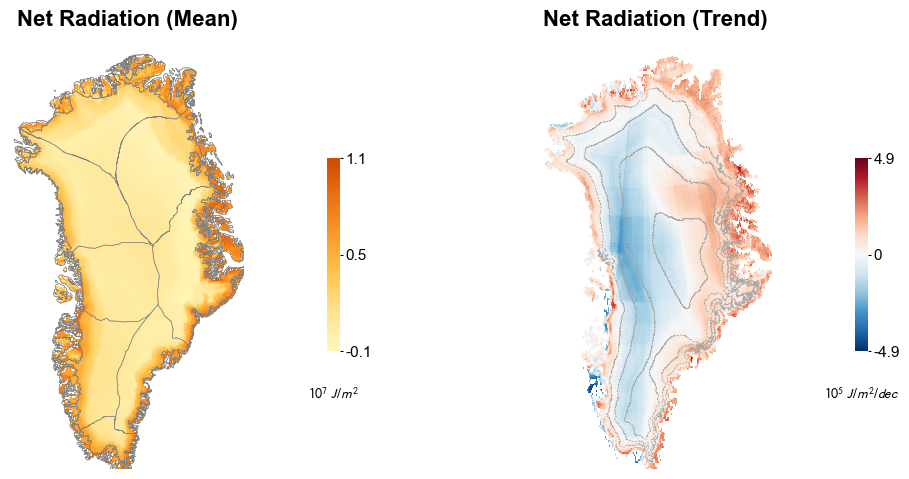


✅ 绘图完成!

📊 图像统计信息:
--------------------------------------------------------------------------------

【夏季净辐射均值】
  最小值: -1.0263e+06 J/m²
  最大值: 1.0684e+07 J/m²
  平均值: 1.9614e+06 J/m²

【夏季净辐射趋势】
  最小值: -4.8720e+05 J/m²/decade
  最大值: 4.4404e+05 J/m²/decade
  平均值: 1.5980e+04 J/m²/decade

【显著性 (p < 0.05)】
  显著格点: 41928/62106 (67.5%)
  显著增加: 23992 格点
  显著减少: 17936 格点

  📈 整体趋势: 夏季净辐射吸收增加


In [5]:
import os#===========================冰盖净吸收辐射 = SSRD × (1 - albedo) + str==========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm, LinearSegmentedColormap
import cartopy.crs as ccrs
import geopandas as gpd

# ================= 1. 环境与字体全局配置 =================
plt.rcParams.update({
    "font.family": "Arial",
    "mathtext.fontset": "stixsans", 
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42
})

TITLE_SIZE, TICK_FONT_SIZE = 16, 11

FIG_WIDTH, FIG_HEIGHT = 11, 5.5
WSPACE = 0.12
LEFT_MARGIN, RIGHT_MARGIN = 0.08, 0.92
TOP_ALIGN, BOTTOM_MARGIN = 0.90, 0.12

DATA_DIR = r"C:\greenland\1995bu\fig4"
CSV_PATH = os.path.join(DATA_DIR, "Greenland_netradiation_MeanTrend.csv")
#SAVE_PATH = os.path.join(DATA_DIR, "Fig_NetRadiation_Summer.png")
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

PROJ = ccrs.NorthPolarStereo(central_longitude=-45)
DATA_CRS = ccrs.PlateCarree()
EXTENT = [-680000, 850000, -3400000, -600000]

# ================= 2. 读取数据 =================
print("=" * 80)
print("📊 绘制夏季净辐射均值和趋势图")
print("=" * 80)

if not os.path.exists(CSV_PATH):
    print(f"❌ 文件不存在: {CSV_PATH}")
    exit()

df = pd.read_csv(CSV_PATH)
print(f"\n✓ 数据读取完成: {df.shape[0]} 个格点")

# ================= 3. 加载矢量数据 =================
print("\n📂 加载矢量边界...")

basins_gdf = None
if os.path.exists(BASIN_DIR):
    basins_all = [gpd.read_file(os.path.join(BASIN_DIR, f)).to_crs("EPSG:4326") 
                  for f in os.listdir(BASIN_DIR) if f.endswith(".shp")]
    if basins_all: 
        basins_gdf = pd.concat(basins_all)
        print(f"  ✓ 流域边界加载完成")

contour_gdf = None
if os.path.exists(CONTOUR_PATH):
    contour_gdf = gpd.read_file(CONTOUR_PATH).to_crs("EPSG:4326")
    print(f"  ✓ 等高线加载完成")

# ================= 4. 数据转换 =================
print("\n🔄 转换数据单位...")

# 均值转换为 10^7 J/m² (与原fig4一致)
df['mean'] /= 1e7

# 趋势转换为 10^5 J/m²/decade (与原fig4一致)
df['trend_per_decade'] /= 1e5

print(f"  ✓ 均值范围: {df['mean'].min():.2f} ~ {df['mean'].max():.2f} (×10^7 J/m²)")
print(f"  ✓ 趋势范围: {df['trend_per_decade'].min():.2f} ~ {df['trend_per_decade'].max():.2f} (×10^5 J/m²/decade)")

# ================= 5. 创建图形 =================
print("\n🎨 开始绘图...")

fig = plt.figure(figsize=(FIG_WIDTH, FIG_HEIGHT))

n_cols = 2
slot_w = (RIGHT_MARGIN - LEFT_MARGIN - WSPACE) / n_cols
h = TOP_ALIGN - BOTTOM_MARGIN

cb_w, cb_gap = 0.012, 0.015
map_w = slot_w - cb_w - cb_gap

# 定义色标
cmap_yellow_orange = LinearSegmentedColormap.from_list(
    "yellow_orange", 
    ["#FFF7BC", "#FEE391", "#FEC44F", "#FB9A29", "#EC7014", "#CC4C02"]
)

# ================= 6. 绘制两个子图 =================
configs = [
    {
        "col": "mean", 
        "title": "Net Radiation (Mean)", 
        "col_idx": 0,
        "unit": r"$10^{7}\ J/m^{2}$",
        "use_diverging": False
    },
    {
        "col": "trend_per_decade", 
        "title": "Net Radiation (Trend)", 
        "col_idx": 1,
        "unit": r"$10^{5}\ J/m^{2}/dec$",
        "use_diverging": True
    },
]

for cfg in configs:
    j = cfg["col_idx"]
    val_col = cfg["col"]
    
    left = LEFT_MARGIN + j * (slot_w + WSPACE)
    bottom = BOTTOM_MARGIN
    
    # 创建地图axes
    ax = fig.add_axes([left, bottom, map_w, h], projection=PROJ)
    ax.set_extent(EXTENT, crs=PROJ)
    ax.axis('off')
    
    # 数据网格化
    grid = df.pivot(index="lat", columns="lon", values=val_col).sort_index()
    
    # 归一化和色标
    if cfg["use_diverging"]:
        # 趋势图：使用红蓝发散色标
        cmap = "RdBu_r"
        vmin, vmax = np.nanmin(grid.values), np.nanmax(grid.values)
        
        # 自动调整中心点
        abs_max = max(abs(vmin), abs(vmax))
        norm = TwoSlopeNorm(vmin=-abs_max, vcenter=0.0, vmax=abs_max)
        ticks = [-abs_max, 0.0, abs_max]
    else:
        # 均值图：使用黄橙色标
        cmap = cmap_yellow_orange
        vmin, vmax = np.nanmin(grid.values), np.nanmax(grid.values)
        norm = Normalize(vmin, vmax)
        ticks = [vmin, (vmin + vmax) / 2, vmax]
    
    # 绘制数据
    im = ax.pcolormesh(
        grid.columns, grid.index, grid.values, 
        transform=DATA_CRS, cmap=cmap, norm=norm, 
        shading="auto", rasterized=True, zorder=3
    )
    
    # 添加矢量边界
    if not cfg["use_diverging"] and basins_gdf is not None:
        ax.add_geometries(
            basins_gdf.geometry, crs=DATA_CRS, 
            edgecolor="grey", facecolor="none", 
            linewidth=0.4, zorder=6
        )
    
    if cfg["use_diverging"] and contour_gdf is not None:
        ax.add_geometries(
            contour_gdf.geometry, crs=DATA_CRS, 
            edgecolor="darkgrey", facecolor='none', 
            linestyle="--", linewidth=0.5, zorder=6
        )
    
    # 色标
    cb_h = h * 0.45
    cb_bottom = bottom + (h - cb_h) / 2
    cb_ax = fig.add_axes([left + map_w + cb_gap, cb_bottom, cb_w, cb_h])
    cb = fig.colorbar(im, cax=cb_ax, ticks=ticks)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=TICK_FONT_SIZE, length=2, pad=2)
    
    # 刻度标签格式化
    tick_labels = []
    for v in ticks:
        if abs(v) < 1e-7:
            label = "0"
        else:
            label = f"{v:.1f}".rstrip('0').rstrip('.')
        tick_labels.append(label)
    cb.ax.set_yticklabels(tick_labels)
    
    # 单位标注
    cb_ax.text(
        0.5, -0.18, cfg["unit"], 
        transform=cb_ax.transAxes, 
        fontsize=TICK_FONT_SIZE - 1, 
        ha="center", va="top"
    )
    
    # 标题
    ax.set_title(cfg["title"], fontsize=TITLE_SIZE, fontweight="bold", pad=10)
    
    print(f"  ✓ 完成: {cfg['title']}")

# ================= 7. 保存图片 =================
print(f"\n💾 保存图片...")
plt.savefig(SAVE_PATH, dpi=400, bbox_inches="tight")
print(f"  ✅ 已保存: {SAVE_PATH}")

plt.show()

print("\n" + "=" * 80)
print("✅ 绘图完成!")
print("=" * 80)

# ================= 8. 额外统计信息 =================
print("\n📊 图像统计信息:")
print("-" * 80)

# 重新读取原始数据（未转换单位）
df_raw = pd.read_csv(CSV_PATH)

print(f"\n【夏季净辐射均值】")
print(f"  最小值: {df_raw['mean'].min():.4e} J/m²")
print(f"  最大值: {df_raw['mean'].max():.4e} J/m²")
print(f"  平均值: {df_raw['mean'].mean():.4e} J/m²")

print(f"\n【夏季净辐射趋势】")
print(f"  最小值: {df_raw['trend_per_decade'].min():.4e} J/m²/decade")
print(f"  最大值: {df_raw['trend_per_decade'].max():.4e} J/m²/decade")
print(f"  平均值: {df_raw['trend_per_decade'].mean():.4e} J/m²/decade")

# 显著性统计
significant = df_raw[df_raw['p_value'] < 0.05]
print(f"\n【显著性 (p < 0.05)】")
print(f"  显著格点: {len(significant)}/{len(df_raw)} ({len(significant)/len(df_raw)*100:.1f}%)")

pos_sig = significant[significant['trend_per_decade'] > 0]
neg_sig = significant[significant['trend_per_decade'] < 0]
print(f"  显著增加: {len(pos_sig)} 格点")
print(f"  显著减少: {len(neg_sig)} 格点")

if df_raw['trend_per_decade'].mean() > 0:
    print(f"\n  📈 整体趋势: 夏季净辐射吸收增加")
else:
    print(f"\n  📉 整体趋势: 夏季净辐射吸收减少")

print("=" * 80)

C:\Users\11823\AppData\Local\Temp\ipykernel_120752\318783292.py:12: UserWarning: The specified chunks separate the stored chunks along dimension "valid_time" starting at index 100. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, chunks={'valid_time': 100})


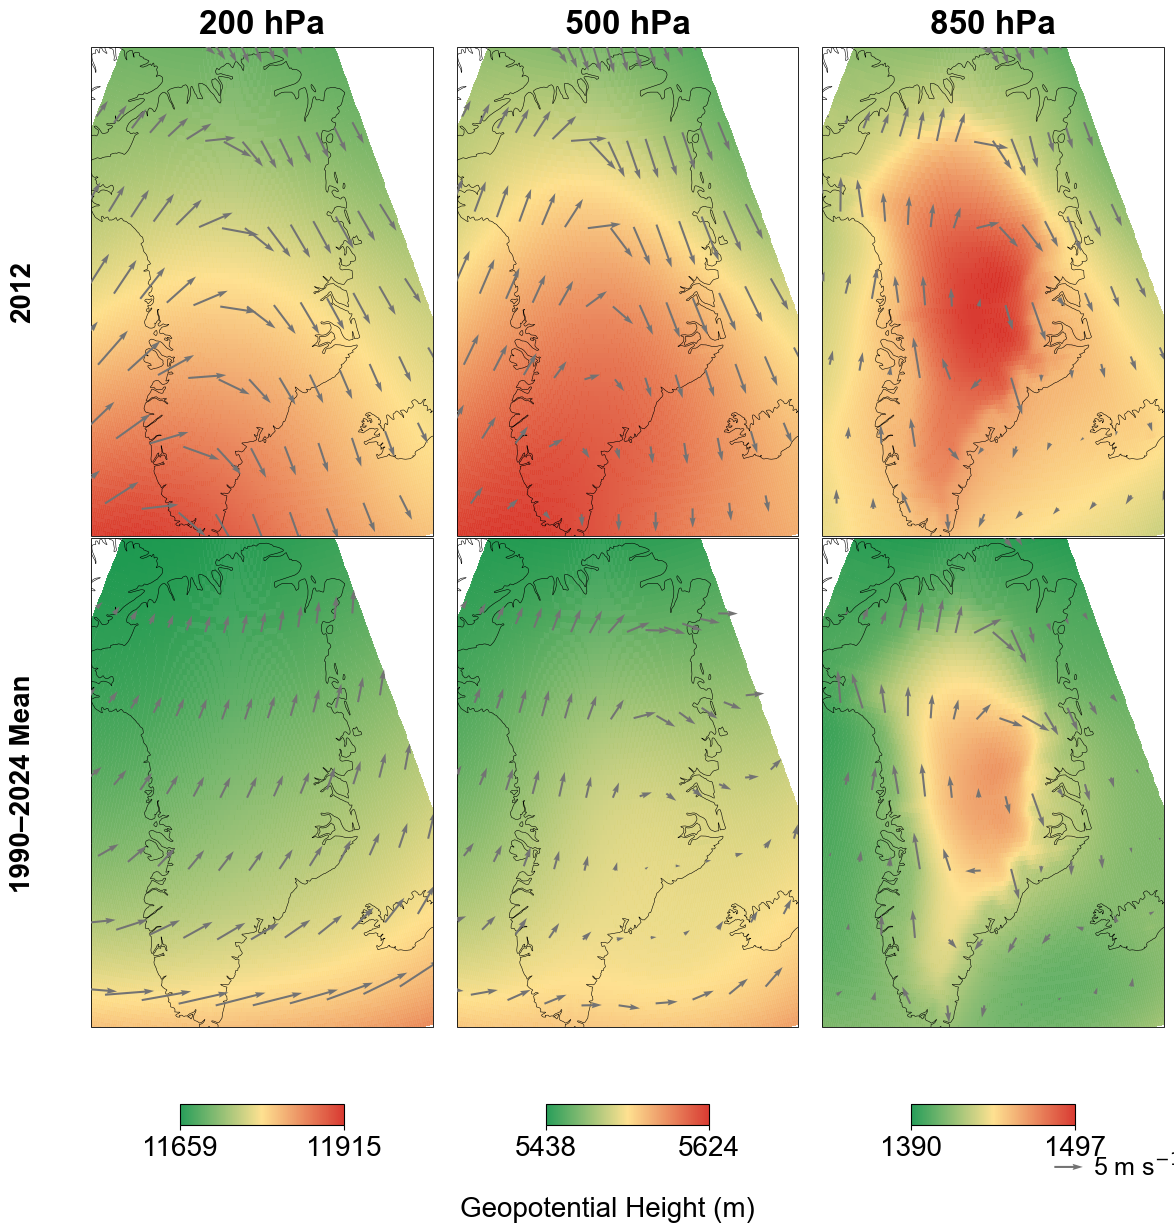

: 

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import sys
from matplotlib.colors import LinearSegmentedColormap

# ===================== 1. 数据加载与 JJA 严格筛选 =====================
def load_and_preprocess(path, levels):
    try:
        ds = xr.open_dataset(path, chunks={'valid_time': 100})
        if 'lat' in ds.coords:
            ds = ds.rename({'lat': 'latitude', 'lon': 'longitude'})

        # 自动识别纬度顺序
        is_desc = ds.latitude[0] > ds.latitude[-1]
        lat_slice = slice(84, 59) if is_desc else slice(59, 84)

        ds_sub = ds[['z', 'u', 'v']].sel(
            pressure_level=levels,
            longitude=slice(-75, -10),
            latitude=lat_slice
        ).compute()

        # 位势高度转 m
        ds_sub["z"] = ds_sub["z"] / 9.80665

        # 2012 JJA
        d_2012 = ds_sub.sel(
            valid_time=slice("2012-06-01", "2012-08-31")
        ).mean("valid_time")

        # 1990–2024 JJA climatology
        clim = ds_sub.sel(valid_time=slice("1990-01-01", "2024-12-31"))
        d_clim = clim.sel(
            valid_time=clim.valid_time.dt.month.isin([6, 7, 8])
        ).mean("valid_time")

        return d_2012, d_clim

    except Exception as e:
        print(f"数据初始化失败: {e}")
        sys.exit(1)


# ===================== 2. 样式 =====================
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 20,
    "axes.titleweight": "bold"
})

# ===================== 3. 自定义配色（红→黄→绿，高→低） =====================
cmap_ryg = LinearSegmentedColormap.from_list(
    "RYG",
    ["#1a9850", "#fee08b", "#d73027"],  # 低 → 中 → 高
    N=256
)

LEVELS = [200, 500, 850]
res_2012, res_clim = load_and_preprocess(
    r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\200500850UVZ.nc",
    LEVELS
)

# 投影
map_proj = ccrs.LambertConformal(central_longitude=-41.5, central_latitude=71)
data_proj = ccrs.PlateCarree()

# ===================== 4. 紧凑布局 =====================
fig = plt.figure(figsize=(13.2, 14))
gs = fig.add_gridspec(
    2, 3,
    wspace=0.005,
    hspace=0.005,
    left=0.10,
    right=0.93,
    top=0.94,
    bottom=0.24
)

rows = [("2012", res_2012), ("1990–2024 Mean", res_clim)]
col_mappables = [None] * 3
last_q = None

for r, (row_label, r_ds) in enumerate(rows):
    for c, lev in enumerate(LEVELS):

        ax = fig.add_subplot(gs[r, c], projection=map_proj)
        ax.set_extent([-58, -18, 59.5, 83.5], crs=data_proj)

        data = r_ds.sel(pressure_level=lev)

        # 同一列统一色标范围（用 2012 + climatology）
        v1 = res_2012.sel(pressure_level=lev).z.values
        v2 = res_clim.sel(pressure_level=lev).z.values
        vmin, vmax = np.nanmin([v1, v2]), np.nanmax([v1, v2])

        # ---- 背景 ----
        im = ax.pcolormesh(
            data.longitude, data.latitude, data.z,
            transform=data_proj,
            cmap=cmap_ryg,
            vmin=vmin, vmax=vmax,
            shading="auto",
            rasterized=True,
            alpha=0.95
        )

        if r == 0:
            col_mappables[c] = (im, vmin, vmax)
            ax.set_title(f"{lev} hPa", pad=10)

        # ---- 风场 ----
        q_ds = data.isel(latitude=slice(None, None, 15),
                         longitude=slice(None, None, 18))
        last_q = ax.quiver(
            q_ds.longitude.values, q_ds.latitude.values,
            q_ds.u.values, q_ds.v.values,
            transform=data_proj,
            color="0.45",
            scale=60,
            width=0.006,
            headwidth=3,
            zorder=5
        )

        # ---- 海岸线 ----
        ax.add_feature(cfeature.COASTLINE, linewidth=0.4, edgecolor="black")

        # ---- 子图框线变细 ----
        for spine in ax.spines.values():
            spine.set_linewidth(0.6)

        # ---- 行标题 ----
        if c == 0:
            ax.text(
                -0.16, 0.5, row_label,
                transform=ax.transAxes,
                rotation=90,
                va="center", ha="right",
                weight="bold"
            )

# ===================== 5. 色标 =====================
for i, (m, vmin, vmax) in enumerate(col_mappables):
    pos = gs[1, i].get_position(fig)
    cax_w = pos.width * 0.45
    cax_x = pos.x0 + (pos.width - cax_w) / 2
    cax = fig.add_axes([cax_x, 0.17, cax_w, 0.015])

    cb = plt.colorbar(m, cax=cax, orientation="horizontal")
    cb.set_ticks([vmin, vmax])
    cb.ax.set_xticklabels([f"{vmin:.0f}", f"{vmax:.0f}"])
    cb.outline.set_linewidth(0.8)

# ===================== 6. 单位 & 风速图例 =====================
fig.text(
    0.5, 0.11,
    "Geopotential Height (m)",
    ha="center", va="center"
)

if last_q:
    plt.quiverkey(
        last_q, 0.86, 0.14,
        5, "5 m s$^{-1}$",
        labelpos="E",
        coordinates="figure",
        fontproperties={"family": "Arial", "size": 18}
    )

plt.show()


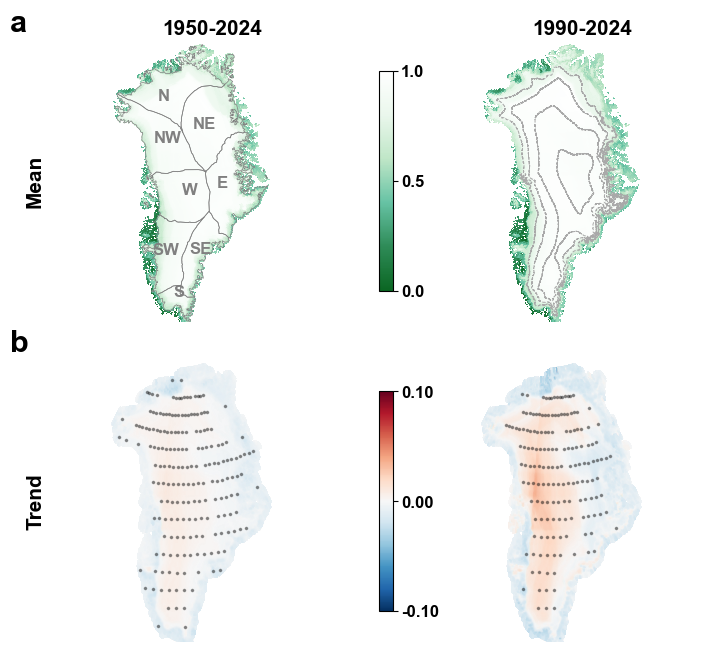

In [36]:
# -*- coding: utf-8 -*-
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.ndimage import zoom, gaussian_filter
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap

# ====================== 1. 版式：关键参数（统一、可控、不会越界） ======================
# 目标：两列图 + 中间色标，所有间距可控且相等
FIG_WIDTH_INCHES = 8
FIG_HEIGHT_INCHES = 7

# 左右边距、列间距、色标宽度（都用 figure 坐标 0~1）
LEFT   = 0.06
RIGHT  = 0.94
GAP    = 0.045          # 两列之间的空隙（色标放在这个空隙中心）
CBAR_W = 0.018          # 色标宽度
CBAR_SHIFT = -0.025     # 色标整体左移

# 顶/底边距 + 行间距（让两行“紧凑且等距”）
TOP    = 0.93
BOTTOM = 0.07
VSPACE = 0.055          # Mean 与 Trend 两行之间的空隙

# 计算每列宽度（保证两列+gap都在[0,1]内）
SUBPLOT_W = (RIGHT - LEFT - GAP) / 2.0
COL_X_POS = [LEFT, LEFT + SUBPLOT_W + GAP]

# 每行高度
ROW_H = (TOP - BOTTOM - VSPACE) / 2.0
ROW_Y = [BOTTOM + ROW_H + VSPACE, BOTTOM]  # [上(Mean), 下(Trend)]

# ====================== 2. 字体与图形风格 ======================
PANEL_LETTER_SIZE = 22
TITLE_SIZE = 15
ROW_LABEL_SIZE = 15
CBAR_TICK_SIZE = 12
BASIN_LABEL_SIZE = 12

# 置信黑点参数
DOT_STEP = 15#==========点的密集程度
DOT_SIZE = 10
DOT_ALPHA = 0.35
DOT_MARKER = '.'

plt.rcParams.update({"font.family": "Arial", "font.size": 14})

# ====================== 3. 数据与投影路径 ======================
DATA_DIR = r"C:\greenland\1995bu\fig4"
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

PROJ = ccrs.NorthPolarStereo(central_longitude=-45)
PC   = ccrs.PlateCarree()
EXTENT = [-57, -19, 59.5, 83.5]

# ====================== 4. 流域名称映射 ======================
BASIN_NAME_MAP = {
    "northwest": "NW", "southwest": "SW", "northeast": "NE", "southeast": "SE",
    "westnorth": "NW", "westsouth": "SW", "eastnorth": "NE", "eastsouth": "SE",
    "northwes": "NW", "southwes": "SW", "northeas": "NE", "southeas": "SE",
    "west": "W", "east": "E", "north": "N", "south": "S", "middle": "M",
    "nw": "NW", "sw": "SW", "ne": "NE", "se": "SE", "w": "W", "e": "E", "n": "N", "s": "S", "m": "M"
}

# ✅ 只保留这 8 个流域缩写，其他任何（例如 ME、M 等）全部不画
VALID_ABBR = {"NW", "NE", "SW", "SE", "W", "E", "N", "S"}

# ====================== 5. 数据处理 ======================
def load_and_grid(csv_name):
    path = os.path.join(DATA_DIR, csv_name)
    df = pd.read_csv(path).dropna(subset=["lat", "lon"])
    mean  = df.pivot_table(index="lat", columns="lon", values="mean", aggfunc='first').sort_index(ascending=True)
    trend = df.pivot_table(index="lat", columns="lon", values="trend_per_decade", aggfunc='first').sort_index(ascending=True)
    sig   = df.pivot_table(index="lat", columns="lon", values="trend_sig95", aggfunc='first').sort_index(ascending=True)
    return mean.index.values, mean.columns.values, mean.values, trend.values, sig.values

def fast_smooth(Z, factor=8, sigma=4):
    mask = np.isfinite(Z)
    Z_filled = np.where(mask, Z, 0)

    Z_zoom = zoom(Z_filled, zoom=(factor, factor), order=1, mode="nearest")
    mask_zoom = zoom(mask.astype(float), zoom=(factor, factor), order=1, mode="nearest")

    Z_smooth = gaussian_filter(Z_zoom, sigma=sigma, mode='nearest')
    mask_smooth = gaussian_filter(mask_zoom, sigma=sigma, mode='nearest')

    out = np.divide(Z_smooth, mask_smooth, where=mask_smooth > 1e-6, out=np.full_like(Z_smooth, np.nan))
    return out

# ====================== 6. 绘图函数 ======================
def draw_basins(ax, basins_gdf):
    if basins_gdf.empty:
        return

    # 只画有效 8 个流域（几何线）
    basins_gdf2 = basins_gdf[basins_gdf["abbr"].isin(VALID_ABBR)]
    if basins_gdf2.empty:
        return

    ax.add_geometries(
        basins_gdf2.geometry, crs=PC, edgecolor="grey",
        facecolor="none", linewidth=0.5, zorder=6
    )

    # ✅ 文字偏移：S 往上，N 往下
    offsets = {
        "NW": (1.0, 0), "SW": (-0.5, 0), "NE": (-1.0, 0), "SE": (1.0, 0),
        "W": (1.5, 0), "E": (-0.8, 0),
        "N": (0, -0.6),   # 往下
        "S": (0, +0.6)    # 往上
    }

    for _, row in basins_gdf2.iterrows():
        abbr = row.get("abbr", "")
        if abbr not in VALID_ABBR:
            continue

        pt = row.geometry.representative_point()
        dx, dy = offsets.get(abbr, (0, 0))
        ax.text(
            pt.x + dx, pt.y + dy, abbr,
            fontsize=BASIN_LABEL_SIZE, fontweight="bold",
            color="grey", ha="center", transform=PC, zorder=10
        )

def draw_colorbar(fig, y0, row_h, cmap, norm, row_type):
    """
    色标位置固定用 GAP，避免 tight/bbox 漂移。
    """
    cx = LEFT + SUBPLOT_W + GAP / 2.0 + CBAR_SHIFT
    h = row_h * 0.78
    cax = fig.add_axes([cx - CBAR_W/2, y0 + (row_h - h)/2, CBAR_W, h])

    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)
    if row_type == "Mean":
        cb.set_ticks([norm.vmin, (norm.vmin + norm.vmax)/2, norm.vmax])
        cb.set_ticklabels(["0.0", "0.5", "1.0"])
    else:
        cb.set_ticks([norm.vmin, 0.0, norm.vmax])
        cb.set_ticklabels([f"{norm.vmin:.2f}", "0.00", f"{norm.vmax:.2f}"])

    cb.ax.tick_params(labelsize=CBAR_TICK_SIZE, pad=2)
    for t in cb.ax.get_yticklabels():
        t.set_fontweight("bold")

# ====================== 7. 预载资源 ======================
basins_all = []
if os.path.exists(BASIN_DIR):
    for f in os.listdir(BASIN_DIR):
        if f.endswith(".shp"):
            gdf = gpd.read_file(os.path.join(BASIN_DIR, f)).to_crs("EPSG:4326")
            basin_name = f.split('.')[0].lower()
            mapped_abbr = BASIN_NAME_MAP.get(basin_name, basin_name.upper()[:2])
            gdf["abbr"] = mapped_abbr
            basins_all.append(gdf)

basins_gdf = pd.concat(basins_all, ignore_index=True) if basins_all else gpd.GeoDataFrame()

contour_gdf = None
if os.path.exists(CONTOUR_PATH):
    contour_gdf = gpd.read_file(CONTOUR_PATH).to_crs("EPSG:4326")

DATA_FILES = [
    ("Greenland_albedo_MeanTrend_sig95.csv", "1950-2024"),
    ("Greenland_1990albedo_MeanTrend_sig95.csv", "1990-2024")
]
cache = {period: load_and_grid(f) for f, period in DATA_FILES}

all_means = np.concatenate([v[2].ravel() for v in cache.values()])
mean_norm = Normalize(vmin=np.nanmin(all_means), vmax=np.nanmax(all_means))
trend_norm = TwoSlopeNorm(vmin=-0.1, vcenter=0.0, vmax=0.1)

colors_mean = ["#0B6623", "#2E8B57", "#66C2A4", "#BFE6C7", "#EAF7EC", "#FFFFFF"]
cmap_mean = LinearSegmentedColormap.from_list("gw", colors_mean, N=256)

# ====================== 8. 绘图 ======================
fig = plt.figure(figsize=(FIG_WIDTH_INCHES, FIG_HEIGHT_INCHES))

for i, row_type in enumerate(["Mean", "Trend"]):
    current_norm = mean_norm if row_type == "Mean" else trend_norm
    current_cmap = cmap_mean if row_type == "Mean" else "RdBu_r"
    y0 = ROW_Y[i]

    for j, (f, period) in enumerate(DATA_FILES):
        ax = fig.add_axes([COL_X_POS[j], y0, SUBPLOT_W, ROW_H], projection=PROJ)
        ax.set_extent(EXTENT, crs=PC)
        ax.axis("off")

        lats, lons, M, T, S = cache[period]

        if row_type == "Mean":
            ax.pcolormesh(
                lons, lats, M, cmap=current_cmap, norm=current_norm,
                transform=PC, zorder=3, shading='auto', rasterized=True
            )
            if j == 0:
                draw_basins(ax, basins_gdf)
            elif contour_gdf is not None:
                ax.add_geometries(
                    contour_gdf.geometry, crs=PC, color="darkgrey",
                    linestyle="--", linewidth=0.7, facecolor='none', zorder=6
                )
        else:
            T_s = fast_smooth(T)
            lf = np.linspace(lons.min(), lons.max(), T_s.shape[1])
            tf = np.linspace(lats.min(), lats.max(), T_s.shape[0])
            ax.pcolormesh(
                lf, tf, T_s, cmap=current_cmap, norm=current_norm,
                transform=PC, zorder=3, shading='gouraud', rasterized=True
            )

            mask = (S >= 0.5) & np.isfinite(S)
            step = DOT_STEP
            yy, xx = np.where(mask[::step, ::step])

            ax.scatter(
                lons[::step][xx], lats[::step][yy],
                s=DOT_SIZE, c="black", alpha=DOT_ALPHA, marker=DOT_MARKER,
                transform=PC, zorder=8, rasterized=True
            )

        if i == 0:
            # ✅ 年份标题往左挪一点：x 从默认 0.5 改为 0.46
            ax.set_title(period, fontsize=TITLE_SIZE, fontweight="bold", pad=4, x=0.46)

    # 行标注（固定体系）
    fig.text(LEFT - 0.035, y0 + ROW_H/2, row_type,
             fontsize=ROW_LABEL_SIZE, fontweight="bold", rotation=90, va="center")
    fig.text(LEFT - 0.055, y0 + ROW_H + 0.012, chr(97 + i),
             fontsize=PANEL_LETTER_SIZE, fontweight="bold")

    draw_colorbar(fig, y0, ROW_H, current_cmap, current_norm, row_type)

# ====================== 9. 保存 ======================
out_png = os.path.join(DATA_DIR, "Fig4_Compact_Optimized.png")
plt.savefig(out_png, dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.show()


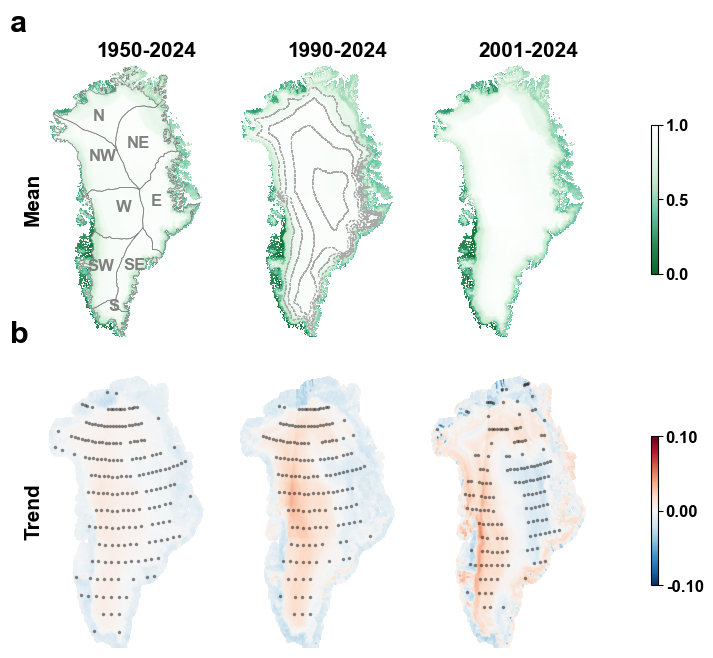

In [11]:
# -*- coding: utf-8 -*-
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.ndimage import zoom, gaussian_filter
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap

# ====================== 1. 版式：极度紧凑（仅修改此处参数） ======================
FIG_WIDTH_INCHES = 7
FIG_HEIGHT_INCHES = 7

LEFT   = 0.05
RIGHT  = 0.90
TOP    = 0.95
BOTTOM = 0.05

# ✅ 关键修改：继续减小间距。使用负值可以抵消投影带来的外部空白 Padding
GAP    = -0.03  # 减小列间距 (从 0.01 调至负值，使子图真正贴合)
VSPACE = -0.01   # 减小行间距 (从 0.055 调至负值)

# 保持原有的色标宽度逻辑
CBAR_SCALE = 0.60
CBAR_W = 0.018 * CBAR_SCALE
CBAR_GAP_RIGHT = 0.01
CBAR_X = RIGHT + CBAR_GAP_RIGHT

# 重新计算位置逻辑
SUBPLOT_W = (RIGHT - LEFT - 2 * GAP) / 3.0
COL_X_POS = [LEFT, LEFT + SUBPLOT_W + GAP, LEFT + 2 * (SUBPLOT_W + GAP)]

ROW_H = (TOP - BOTTOM - VSPACE) / 2.0
ROW_Y = [BOTTOM + ROW_H + VSPACE, BOTTOM]

# ====================== 2. 还原所有视觉样式 (完全保持您第一版代码的参数) ======================
PANEL_LETTER_SIZE = 22
TITLE_SIZE = 15
ROW_LABEL_SIZE = 15
CBAR_TICK_SIZE = 12
BASIN_LABEL_SIZE = 12

DOT_STEP = 15
DOT_STEP_LASTCOL = 12 
DOT_SIZE = 10
DOT_ALPHA = 0.35
DOT_MARKER = '.'

plt.rcParams.update({"font.family": "Arial", "font.size": 14})

# ====================== 3-5. 数据处理逻辑 (完全还原) ======================
# [此处保持您原始 load_and_grid, fast_smooth 函数不变]

# ====================== 6. 绘图函数 (完全还原) ======================
def draw_basins(ax, basins_gdf):
    # [保持您原始 draw_basins 逻辑不变，包括 offsets 和字体颜色]
    if basins_gdf.empty: return
    basins_gdf2 = basins_gdf[basins_gdf["abbr"].isin(VALID_ABBR)]
    ax.add_geometries(basins_gdf2.geometry, crs=PC, edgecolor="grey", facecolor="none", linewidth=0.5, zorder=6)
    
    offsets = {"NW": (1.0, 0), "SW": (-0.5, 0), "NE": (-1.0, 0), "SE": (1.0, 0), "W": (1.5, 0), "E": (-0.8, 0), "N": (0, -0.6), "S": (0, +0.6)}
    for _, row in basins_gdf2.iterrows():
        abbr = row.get("abbr", "")
        pt = row.geometry.representative_point()
        dx, dy = offsets.get(abbr, (0, 0))
        ax.text(pt.x + dx, pt.y + dy, abbr, fontsize=BASIN_LABEL_SIZE, fontweight="bold", color="grey", ha="center", transform=PC, zorder=10)

def draw_row_colorbar(fig, y0, row_h, cmap, norm, row_type):
    # [保持您原始色标数值逻辑不变]
    base_h = row_h * 0.78
    h = base_h * CBAR_SCALE
    cax = fig.add_axes([CBAR_X, y0 + (row_h - h)/2, CBAR_W, h])
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)
    if row_type == "Mean":
        cb.set_ticks([norm.vmin, (norm.vmin + norm.vmax) / 2, norm.vmax])
        cb.set_ticklabels(["0.0", "0.5", "1.0"])
    else:
        cb.set_ticks([norm.vmin, 0.0, norm.vmax])
        cb.set_ticklabels([f"{norm.vmin:.2f}", "0.00", f"{norm.vmax:.2f}"])
    cb.ax.tick_params(labelsize=CBAR_TICK_SIZE, pad=2)
    for t in cb.ax.get_yticklabels(): t.set_fontweight("bold")

# ====================== 7-8. 数据加载与核心循环 (完全还原) ======================
# ... [中间加载代码保持不变] ...

fig = plt.figure(figsize=(FIG_WIDTH_INCHES, FIG_HEIGHT_INCHES))

for i, row_type in enumerate(["Mean", "Trend"]):
    current_norm = mean_norm if row_type == "Mean" else trend_norm
    current_cmap = cmap_mean if row_type == "Mean" else "RdBu_r"
    y0 = ROW_Y[i]

    for j, (csv_name, period) in enumerate(DATA_FILES):
        ax = fig.add_axes([COL_X_POS[j], y0, SUBPLOT_W, ROW_H], projection=PROJ)
        ax.set_extent(EXTENT, crs=PC)
        ax.axis("off")

        lats, lons, M, T, S = cache[period]

        if row_type == "Mean":
            ax.pcolormesh(lons, lats, M, cmap=current_cmap, norm=current_norm, transform=PC, zorder=3, shading='auto', rasterized=True)
            if j == 0: draw_basins(ax, basins_gdf)
            elif j == 1 and contour_gdf is not None:
                ax.add_geometries(contour_gdf.geometry, crs=PC, color="darkgrey", linestyle="--", linewidth=0.7, facecolor='none', zorder=6)
        else:
            T_s = fast_smooth(T)
            lf = np.linspace(lons.min(), lons.max(), T_s.shape[1])
            tf = np.linspace(lats.min(), lats.max(), T_s.shape[0])
            ax.pcolormesh(lf, tf, T_s, cmap=current_cmap, norm=current_norm, transform=PC, zorder=3, shading='gouraud', rasterized=True)
            
            # ✅ 还原您的打点密度逻辑
            step = DOT_STEP_LASTCOL if j == 2 else DOT_STEP
            mask = (S >= 0.5) & np.isfinite(S)
            yy, xx = np.where(mask[::step, ::step])
            ax.scatter(lons[::step][xx], lats[::step][yy], s=DOT_SIZE, c="black", alpha=DOT_ALPHA, marker=DOT_MARKER, transform=PC, zorder=8, rasterized=True)

        if i == 0:
            # 还原您指定的 title 位置
            ax.set_title(period, fontsize=TITLE_SIZE, fontweight="bold", pad=4, x=0.46)

    # 还原侧边标签
    fig.text(LEFT - 0.035, y0 + ROW_H/2, row_type, fontsize=ROW_LABEL_SIZE, fontweight="bold", rotation=90, va="center")
    fig.text(LEFT - 0.055, y0 + ROW_H + 0.012, chr(97 + i), fontsize=PANEL_LETTER_SIZE, fontweight="bold")

    draw_row_colorbar(fig, y0, ROW_H, current_cmap, current_norm, row_type)

# ====================== 9. 保存 ======================
out_png = os.path.join(DATA_DIR, "Fig4_Tight_V3.png")
plt.savefig(out_png, dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.show()

绘图完成！底图已切换为 1950-2024 Trend (c图)，已保存至: C:\greenland\1995bu\fig4\Fig4_Trend_C_Special.png


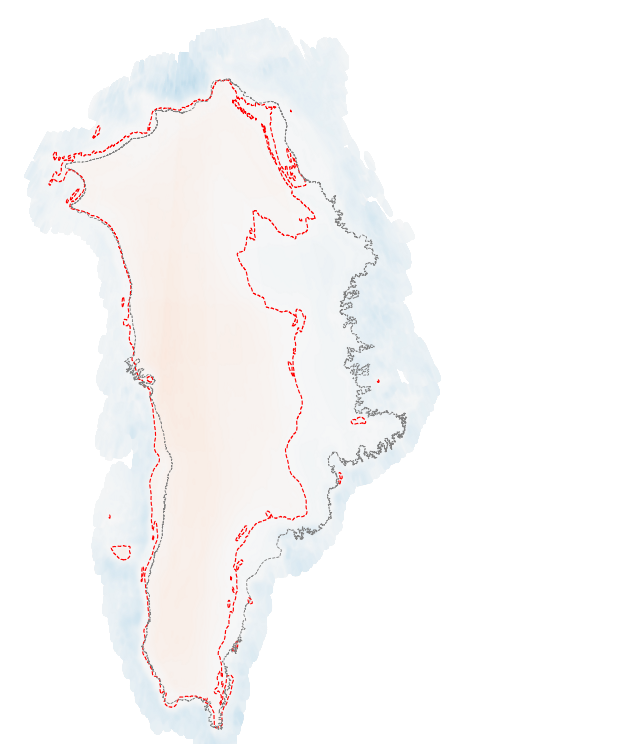

In [17]:
# -*- coding: utf-8 -*-
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.ndimage import zoom, gaussian_filter
from matplotlib.colors import TwoSlopeNorm

# ====================== 1. 路径与核心参数 ======================
DATA_DIR = r"C:\greenland\1995bu\fig4"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

# 【切换为 c 图对应的数据文件：1950-2024】
TARGET_FILE = "Greenland_albedo_MeanTrend_sig95.csv"

# 绘图版式参数（仅保留绘图区，不留边距给标题和色标）
FIG_WIDTH_INCHES = 6
FIG_HEIGHT_INCHES = 8

PROJ = ccrs.NorthPolarStereo(central_longitude=-45)
PC   = ccrs.PlateCarree()
EXTENT = [-57, -19, 59.5, 83.5]

# ====================== 2. 数据处理函数 ======================
def fast_smooth(Z, factor=8, sigma=4):
    mask = np.isfinite(Z)
    Z_filled = np.where(mask, Z, 0)
    Z_zoom = zoom(Z_filled, zoom=(factor, factor), order=1, mode="nearest")
    mask_zoom = zoom(mask.astype(float), zoom=(factor, factor), order=1, mode="nearest")
    Z_smooth = gaussian_filter(Z_zoom, sigma=sigma, mode='nearest')
    mask_smooth = gaussian_filter(mask_zoom, sigma=sigma, mode='nearest')
    return np.divide(Z_smooth, mask_smooth, where=mask_smooth > 1e-6, out=np.full_like(Z_smooth, np.nan))

# ====================== 3. 绘图执行 ======================
plt.rcParams.update({"font.family": "Arial"})
fig = plt.figure(figsize=(FIG_WIDTH_INCHES, FIG_HEIGHT_INCHES))

# 3.1 加载并网格化 Trend 数据 (1950-2024)
df = pd.read_csv(os.path.join(DATA_DIR, TARGET_FILE)).dropna(subset=["lat", "lon"])
trend_grid = df.pivot_table(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
lats, lons = trend_grid.index.values, trend_grid.columns.values

# 执行平滑
T_s = fast_smooth(trend_grid.values)
lf = np.linspace(lons.min(), lons.max(), T_s.shape[1])
tf = np.linspace(lats.min(), lats.max(), T_s.shape[0])

# 3.2 创建子图 (占据整个画布，不显示坐标轴)
ax = fig.add_axes([0, 0, 1, 1], projection=PROJ)
ax.set_extent(EXTENT, crs=PC)
ax.axis("off")

# 3.3 绘制 Trend 底图
trend_norm = TwoSlopeNorm(vmin=-0.1, vcenter=0.0, vmax=0.1)
ax.pcolormesh(lf, tf, T_s, cmap="RdBu_r", norm=trend_norm, 
              transform=PC, zorder=3, shading='gouraud', rasterized=True)

# 3.4 绘制线组 A: Trend > 0 的边界 (红色虚线)
pos_mask = np.zeros_like(T_s)
pos_mask[(T_s > 0) & np.isfinite(T_s)] = 1
ax.contour(lf, tf, pos_mask, levels=[0.5], 
           colors=['red'], linestyles='--', linewidths=0.8, 
           transform=PC, zorder=9)

# 3.5 绘制线组 B: 1500m 等高线 (更细的灰色虚线)
if os.path.exists(CONTOUR_PATH):
    c_gdf = gpd.read_file(CONTOUR_PATH).to_crs("EPSG:4326")
    c_1500 = c_gdf[c_gdf['Contour'] == 1500]
    if not c_1500.empty:
        ax.add_geometries(c_1500.geometry, crs=PC, 
                          edgecolor="grey", linestyle="--", linewidth=0.6, 
                          facecolor='none', zorder=10)

# ====================== 4. 输出 ======================
# 不设标题、不设色标，直接保存
out_path = os.path.join(DATA_DIR, "Fig4_Trend_C_Special.png")
# bbox_inches="tight" 会确保去掉所有多余白边
plt.savefig(out_path, dpi=300, bbox_inches="tight", pad_inches=0)
print(f"绘图完成！底图已切换为 1950-2024 Trend (c图)，已保存至: {out_path}")
plt.show()